# PRCP-1001 · Rice Leaf Disease Detection

**Domain:** Agriculture / Computer Vision  **Task type:** Multi-class image classification (3 classes)

| Task | Where in this notebook |
|---|---|
| **Task 1** – Complete data analysis report | §1 Data Cleaning, §2 EDA, §3 Preprocessing, §4 Feature Engineering |
| **Task 2** – Model to classify the 3 rice leaf diseases | §5 Baseline models, §6 Model improvement, §8 Production export |
| **Task 3** – Analysis of techniques such as Data Augmentation | §4.5, §6, §9 |
| Model Comparison Report | §7 |
| Report on Challenges Faced | §10 |
| Conclusion, observations & suggestions | §11 |

**Dataset:** 3 classes of disease-infected rice-leaf photographs – *Bacterial leaf blight*, *Brown spot*, *Leaf smut*.
(The problem statement mentions "leaf blast", but the data provided contains **Leaf smut**, so that is what is modelled.)

## 0. Setup

In [1]:
import os, sys, time, json, hashlib, shutil, warnings, random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import ndimage, stats

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

ROOT = Path.cwd().parent if (Path.cwd().parent / "Data").exists() else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from riceleaf.preprocess import load_image, crop_to_leaf, preprocess, leaf_mask, IMG_SIZE, CLASS_NAMES

RAW_DIR   = ROOT / "Data"
CLEAN_DIR = ROOT / "data_clean"
MODEL_DIR = ROOT / "models";            MODEL_DIR.mkdir(exist_ok=True)
FIG_DIR   = ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="Set2")
PALETTE = dict(zip(CLASS_NAMES, sns.color_palette("Set2", 3)))
pd.set_option("display.max_colwidth", 60)
print("Project root:", ROOT)

Project root: E:\PRCP-1001-RiceLeaf


## 1. Data Cleaning
Image data has no NaNs, but it has its own quality problems. We check:
1. **Inventory**: which files exist, their class, extension and naming.
2. **Integrity**: can every file be decoded? What colour mode is it in?
3. **Exact duplicates**: identical bytes (MD5).
4. **Near duplicates**: the same photo re-saved or resized (perceptual *dHash*).
5. **Quality outliers**: very blurry, very dark or overexposed images.
6. **Standardise & export**: consistent names, lowercase `.jpg`, RGB, plus a manifest CSV.

### 1.1 Inventory

In [2]:
def class_from_dir(p: Path) -> str:
    return p.parent.name                     # e.g. 'Brown spot' (outer folder has a zip timestamp suffix)

files = sorted(p for p in RAW_DIR.rglob("*") if p.is_file())
inv = pd.DataFrame({
    "path": files,
    "class": [class_from_dir(p) for p in files],
    "filename": [p.name for p in files],
    "ext": [p.suffix for p in files],
    "file_kb": [p.stat().st_size / 1024 for p in files],
})
print("Total files:", len(inv))
display(inv.groupby("class").agg(n_files=("filename", "size")).assign(expected=40))
display(inv["ext"].value_counts().rename("count").to_frame())
inv.head()

Total files: 119


,n_files,expected
class,,
Bacterial leaf blight,40,40
Brown spot,40,40
Leaf smut,39,40


,count
ext,
.JPG,67
.jpg,52


,path,class,filename,ext,file_kb
0,E:\PRCP-1001-RiceLeaf\Data\Bacterial leaf blight-2020081...,Bacterial leaf blight,DSC_0365.JPG,.JPG,456.161133
1,E:\PRCP-1001-RiceLeaf\Data\Bacterial leaf blight-2020081...,Bacterial leaf blight,DSC_0366.jpg,.jpg,408.133789
2,E:\PRCP-1001-RiceLeaf\Data\Bacterial leaf blight-2020081...,Bacterial leaf blight,DSC_0367.JPG,.JPG,442.016602
3,E:\PRCP-1001-RiceLeaf\Data\Bacterial leaf blight-2020081...,Bacterial leaf blight,DSC_0370.jpg,.jpg,418.683594
4,E:\PRCP-1001-RiceLeaf\Data\Bacterial leaf blight-2020081...,Bacterial leaf blight,DSC_0372.JPG,.JPG,470.204102


### 1.2 Integrity check (decode every image)

In [3]:
def inspect(path):
    try:
        with Image.open(path) as im:
            im.verify()                              # structural check
        with Image.open(path) as im:
            im.load()                                # full decode
            return dict(ok=True, width=im.width, height=im.height, mode=im.mode, fmt=im.format)
    except Exception as e:
        return dict(ok=False, width=np.nan, height=np.nan, mode=None, fmt=None, error=str(e))

inv = pd.concat([inv, pd.DataFrame([inspect(p) for p in inv.path])], axis=1)
print("Corrupt / unreadable files:", (~inv.ok).sum())
print("Colour modes:", inv["mode"].value_counts().to_dict(), "| formats:", inv["fmt"].value_counts().to_dict())

Corrupt / unreadable files: 0
Colour modes: {'RGB': 119} | formats: {'JPEG': 119}


### 1.3 Exact duplicates (MD5 hash)

In [4]:
inv["md5"] = [hashlib.md5(p.read_bytes()).hexdigest() for p in inv.path]
dup_exact = inv[inv.duplicated("md5", keep=False)]
print("Exact duplicate files:", len(dup_exact))
dup_exact

Exact duplicate files: 0


,path,class,filename,ext,file_kb,ok,width,height,mode,fmt,md5


### 1.4 Near duplicates (perceptual difference hash)

In [5]:
def dhash(path, size=8):
    g = np.asarray(load_image(path).convert("L").resize((size + 1, size), Image.Resampling.LANCZOS), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten()

hashes = np.stack([dhash(p) for p in inv.path])
ham = (hashes[:, None, :] != hashes[None, :, :]).sum(-1)
pairs = [(i, j, ham[i, j]) for i in range(len(inv)) for j in range(i + 1, len(inv)) if ham[i, j] <= 5]
near = pd.DataFrame([(inv.filename[i], inv["class"][i], inv.filename[j], inv["class"][j], d) for i, j, d in pairs],
                    columns=["file_a", "class_a", "file_b", "class_b", "hamming"])
print(f"Near-duplicate pairs (Hamming distance <= 5 of 64 bits): {len(near)}")
near

Near-duplicate pairs (Hamming distance <= 5 of 64 bits): 0


,file_a,class_a,file_b,class_b,hamming


In [6]:
if len(near):
    fig, axes = plt.subplots(len(near[:4]), 2, figsize=(10, 2.2 * len(near[:4])), squeeze=False)
    for r, (_, row) in enumerate(near[:4].iterrows()):
        for c, f in enumerate([row.file_a, row.file_b]):
            axes[r, c].imshow(load_image(inv.loc[inv.filename == f, "path"].iloc[0])); axes[r, c].axis("off")
            axes[r, c].set_title(f"{f} (d={row.hamming})", fontsize=9)
    plt.tight_layout(); plt.show()

### 1.5 Quality outliers – blur, brightness, exposure

In [7]:
def quality(path):
    im = load_image(path); im.thumbnail((800, 800))
    g = np.asarray(im.convert("L"), dtype=np.float32)
    return dict(blur_var=ndimage.laplace(g).var(),          # variance of Laplacian: low = blurry
                brightness=g.mean(), contrast=g.std(),
                overexposed_pct=(g > 250).mean() * 100)

inv = pd.concat([inv, pd.DataFrame([quality(p) for p in inv.path])], axis=1)

def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); return (s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))

inv["blur_flag"] = inv.blur_var < inv.blur_var.quantile(0.05)
inv["bright_flag"] = iqr_outliers(inv.brightness)
display(inv[["blur_var", "brightness", "contrast", "overexposed_pct"]].describe().T.round(2))
print("Flagged as blurriest 5%:", inv.blur_flag.sum(), "| brightness outliers:", inv.bright_flag.sum())

,count,mean,std,min,25%,50%,75%,max
blur_var,119.0,225.70,263.17,21.84,56.56,108.66,301.61,1314.39
brightness,119.0,182.02,24.47,89.50,175.59,187.36,196.26,235.27
contrast,119.0,53.45,10.47,17.52,49.02,52.71,57.55,86.33
overexposed_pct,119.0,9.51,19.23,0.00,0.00,0.00,5.98,82.04


Flagged as blurriest 5%: 6 | brightness outliers: 12


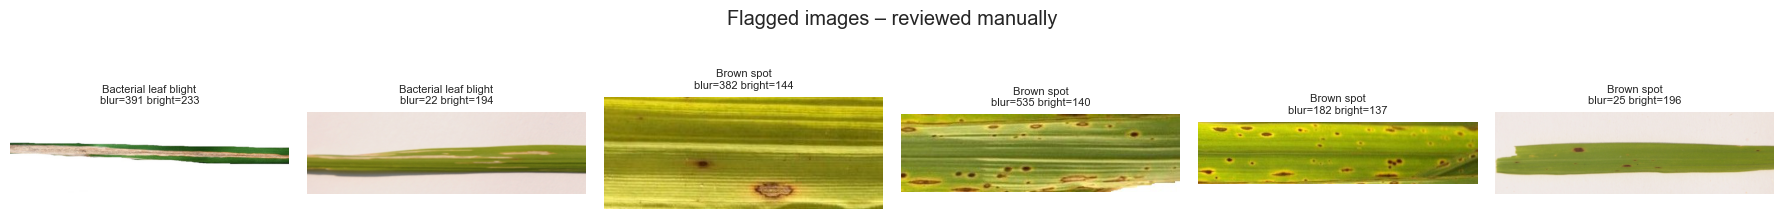

In [8]:
flag = inv[inv.blur_flag | inv.bright_flag]
fig, axes = plt.subplots(1, min(6, len(flag)), figsize=(18, 2.6), squeeze=False)
for ax, (_, r) in zip(axes[0], flag.head(6).iterrows()):
    ax.imshow(load_image(r.path)); ax.axis("off")
    ax.set_title(f"{r['class']}\nblur={r.blur_var:.0f} bright={r.brightness:.0f}", fontsize=8)
plt.suptitle("Flagged images – reviewed manually"); plt.tight_layout(); plt.show()

**Decision:** flagged images were **reviewed visually and kept**. The lesions are still clearly visible, and with only
~40 images per class, dropping valid samples costs more than it gains. The flags show *variation in capture
conditions* that the model has to handle, not bad data.

### 1.6 Standardise names / format and export the clean dataset

In [9]:
def slug(c): return c.lower().replace(" ", "_")

clean = inv[inv.ok].drop_duplicates("md5").copy()          # drop corrupt + exact duplicates (none found, but kept for safety)
clean["is_standard_size"] = (clean.width == 3081) & (clean.height == 897)
clean["clean_name"] = clean.groupby("class").cumcount().add(1).map("{:03d}".format)
clean["clean_name"] = clean["class"].map(slug) + "_" + clean["clean_name"] + ".jpg"

if CLEAN_DIR.exists(): shutil.rmtree(CLEAN_DIR)
for _, r in clean.iterrows():
    out = CLEAN_DIR / slug(r["class"]) / r.clean_name
    out.parent.mkdir(parents=True, exist_ok=True)
    load_image(r.path).save(out, quality=95)                # RGB, EXIF-rotation applied, lowercase .jpg
clean["clean_path"] = [str(CLEAN_DIR / slug(c) / n) for c, n in zip(clean["class"], clean.clean_name)]
clean.drop(columns=["path"]).to_csv(CLEAN_DIR / "manifest.csv", index=False)

summary = pd.DataFrame({
    "raw files": inv.groupby("class").size(),
    "corrupt": inv[~inv.ok].groupby("class").size(),
    "exact dups removed": inv.groupby("class").size() - inv[inv.ok].drop_duplicates("md5").groupby("class").size(),
    "clean images": clean.groupby("class").size(),
}).fillna(0).astype(int)
summary.loc["TOTAL"] = summary.sum()
summary

,raw files,corrupt,exact dups removed,clean images
class,,,,
Bacterial leaf blight,40,0,0,40
Brown spot,40,0,0,40
Leaf smut,39,0,0,39
TOTAL,119,0,0,119


### 📝 Observations – Data Cleaning
* **119 images, not 120**: *Leaf smut* has 39 files, so one image is missing from the provided zip. The classes are still
  effectively balanced (40 / 40 / 39), so no resampling is needed.
* **Integrity is good:** 0 corrupt files, all JPEG, all RGB, **0 exact duplicates (MD5)** and **0 near-duplicates (dHash ≤ 5)**.
  That last check matters: duplicates split across train and test would inflate the test score.
* **Inconsistent naming:** 67 `.JPG` vs 52 `.jpg`, and camera names (`DSC_0365`) that don't mention the class. The clean copy uses
  `class_NNN.jpg` with a `manifest.csv` holding the image metadata.
* **Quality flags:** 6 blurriest-5% images and 12 brightness outliers. After visual review they are **kept**: the lesions
  are visible, and they represent real capture variation that the model should learn to handle.

## 2. Exploratory Data Analysis (EDA)

### 2.1 Class distribution

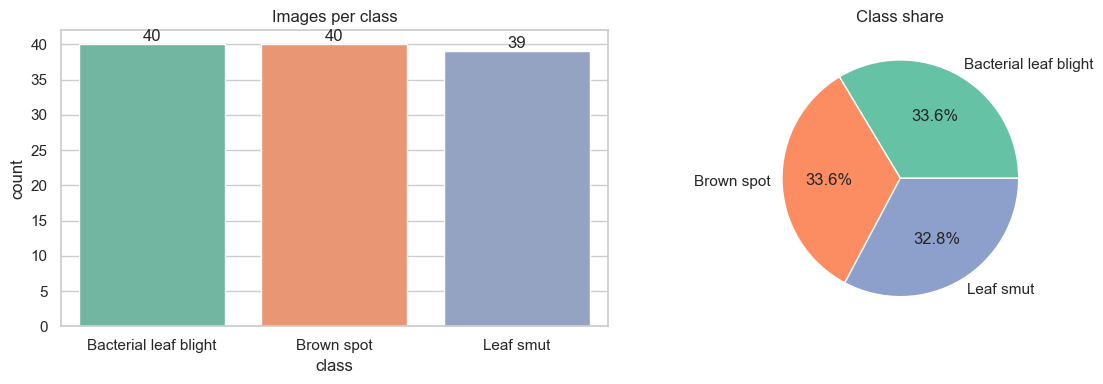

Imbalance ratio (max/min): 1.026


In [10]:
counts = clean["class"].value_counts().reindex(CLASS_NAMES)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax[0], palette=PALETTE)
for i, v in enumerate(counts.values): ax[0].text(i, v + .5, v, ha="center")
ax[0].set(title="Images per class", ylabel="count")
ax[1].pie(counts, labels=counts.index, autopct="%1.1f%%", colors=[PALETTE[c] for c in counts.index]); ax[1].set_title("Class share")
plt.tight_layout(); fig.savefig(FIG_DIR / "class_distribution.png", dpi=110); plt.show()
print("Imbalance ratio (max/min):", round(counts.max() / counts.min(), 3))

### 2.2 Sample images per class

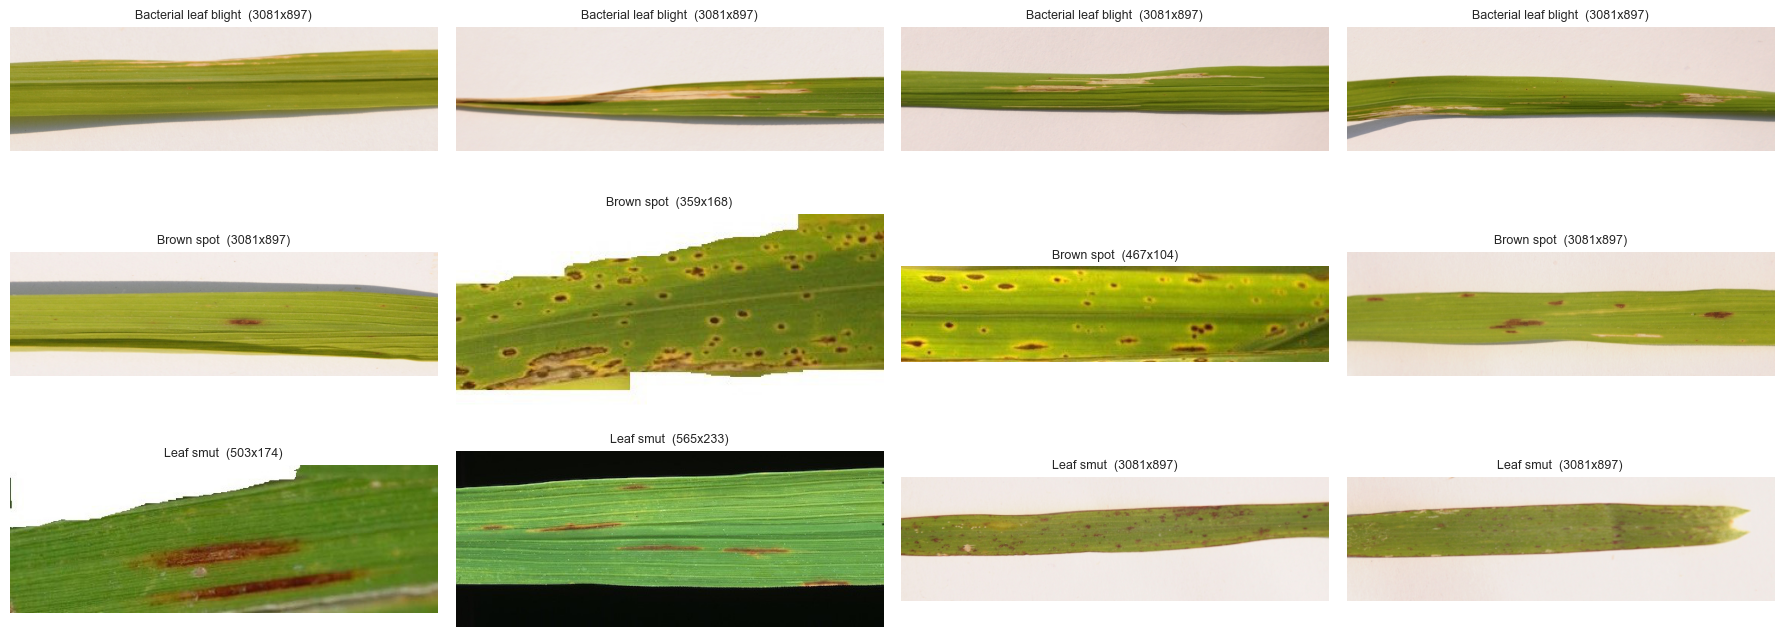

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(18, 7))
for r, c in enumerate(CLASS_NAMES):
    for k, (_, row) in enumerate(clean[clean["class"] == c].sample(4, random_state=SEED).iterrows()):
        axes[r, k].imshow(load_image(row.clean_path)); axes[r, k].axis("off")
        axes[r, k].set_title(f"{c}  ({row.width}x{row.height})", fontsize=9)
plt.tight_layout(); plt.show()

### 2.3 Image dimensions & aspect ratio – checking for a *shortcut* signal

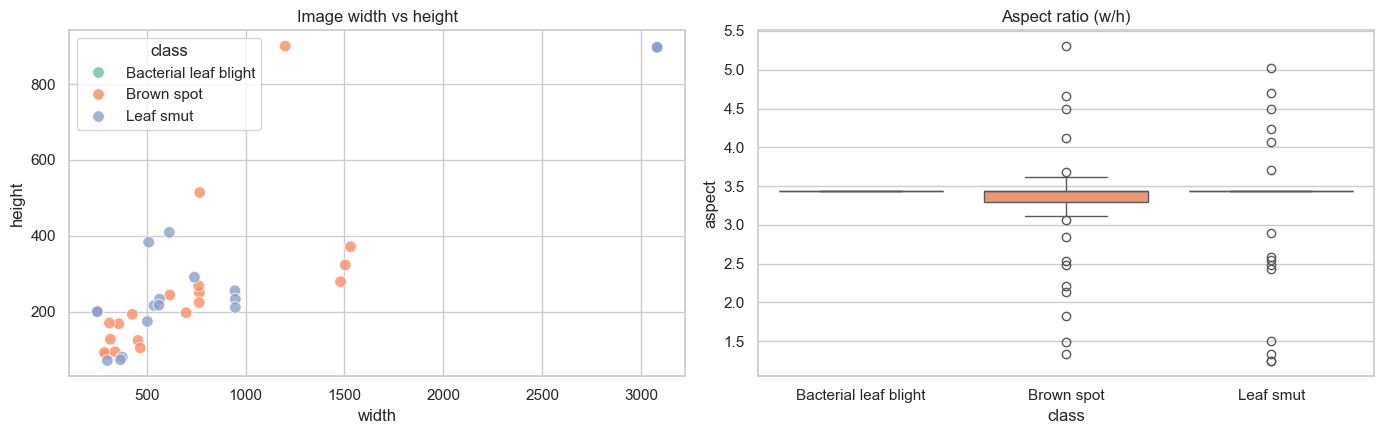

is_standard_size,3081x897 (standard),other size,All
class,,,
Bacterial leaf blight,40,0,40
Brown spot,21,19,40
Leaf smut,24,15,39
All,85,34,119


In [12]:
clean["aspect"] = clean.width / clean.height
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(data=clean, x="width", y="height", hue="class", palette=PALETTE, s=70, alpha=.8, ax=ax[0])
ax[0].set_title("Image width vs height")
sns.boxplot(data=clean, x="class", y="aspect", palette=PALETTE, ax=ax[1]); ax[1].set_title("Aspect ratio (w/h)")
plt.tight_layout(); plt.show()
display(pd.crosstab(clean["class"], clean.is_standard_size.map({True: "3081x897 (standard)", False: "other size"}), margins=True))

### 2.4 File size

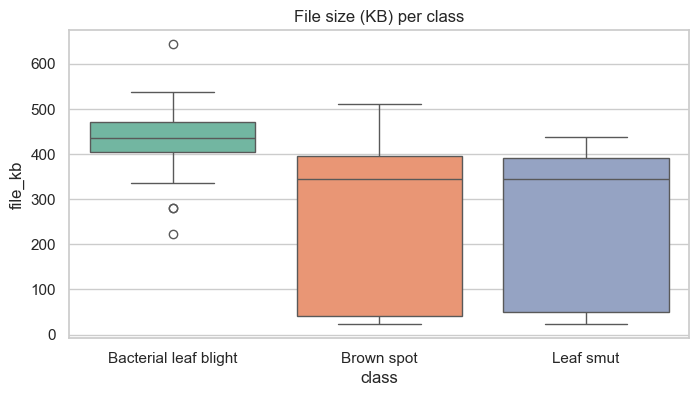

class          Bacterial leaf blight  Brown spot  Leaf smut
width   count                   40.0        40.0       39.0
        mean                  3081.0      1951.3     2111.8
        std                      0.0      1237.3     1250.6
        min                   3081.0       286.0      250.0
        25%                   3081.0       678.5      589.5
        50%                   3081.0      3081.0     3081.0
        75%                   3081.0      3081.0     3081.0
        max                   3081.0      3081.0     3081.0
height  count                   40.0        40.0       39.0
        mean                   897.0       589.2      635.2
        std                      0.0       352.7      340.7
        min                    897.0        88.0       71.0
        25%                    897.0       217.2      233.0
        50%                    897.0       897.0      897.0
        75%                    897.0       897.0      897.0
        max                    897.0       900.0      897.0
file_kb count                   40.0        40.0       39.0
        mean                   432.9       240.2      248.7
        std                     73.4       184.3      165.5
        min                    223.0        22.8       23.7
        25%                    404.9        40.7       49.6
        50%                    436.5       345.2      345.6
        75%                    471.0       394.9      391.3
        max                    643.4       509.9      437.0

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=clean, x="class", y="file_kb", palette=PALETTE, ax=ax); ax.set_title("File size (KB) per class")
plt.show()
clean.groupby("class")[["width", "height", "file_kb"]].describe().round(1).T

### 2.5 Colour analysis (leaf pixels only)
Statistics are computed **only on leaf pixels** (saturation mask). Otherwise the white background would dominate
the numbers.

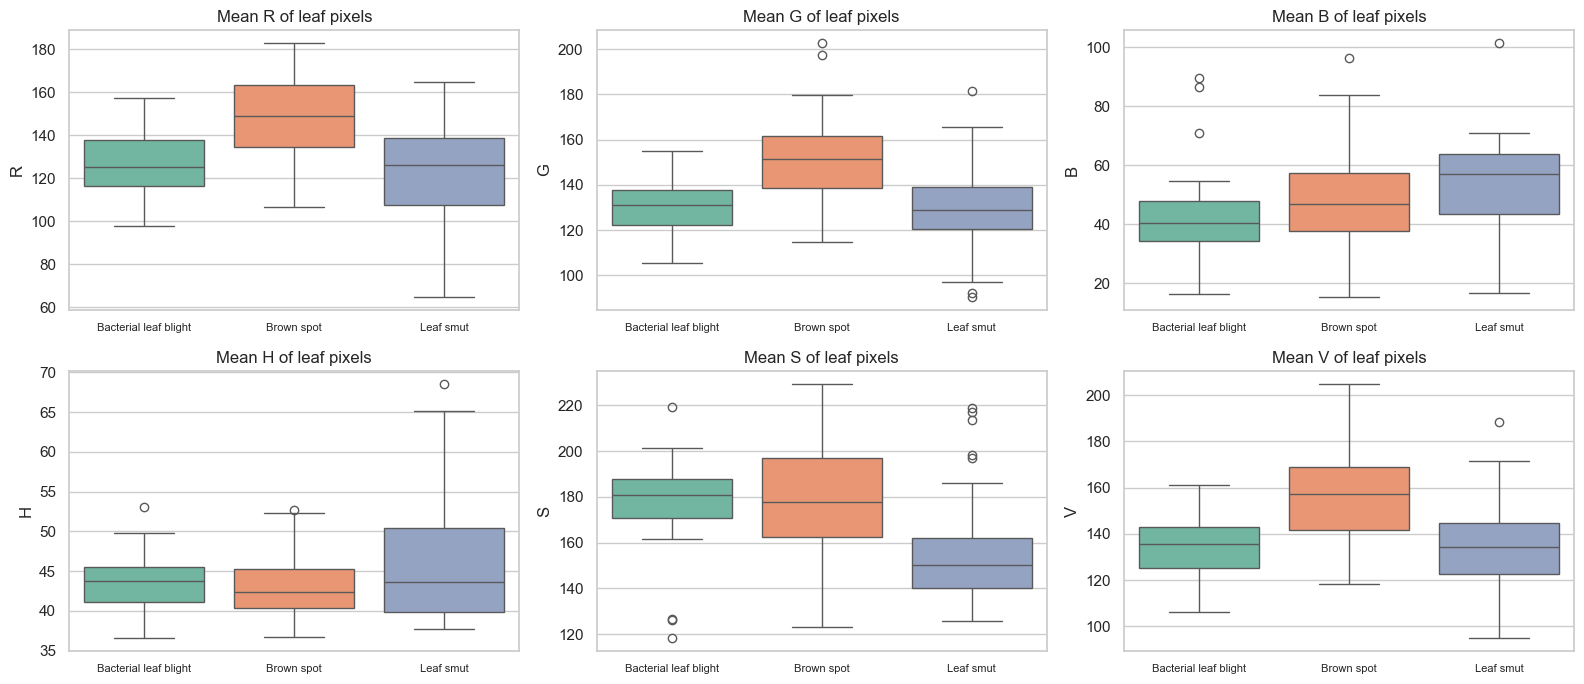

In [14]:
def colour_stats(path):
    im = crop_to_leaf(load_image(path)); im.thumbnail((600, 600))
    m = leaf_mask(im)
    rgb = np.asarray(im)[m]; hsv = np.asarray(im.convert("HSV"))[m]
    hue = hsv[:, 0]
    return dict(R=rgb[:, 0].mean(), G=rgb[:, 1].mean(), B=rgb[:, 2].mean(),
                H=hue.mean(), S=hsv[:, 1].mean(), V=hsv[:, 2].mean(),
                leaf_area_pct=m.mean() * 100,
                brownish_pct=(hue < 38).mean() * 100,        # hue < ~54 deg: brown/yellow lesion tissue
                dark_spot_pct=(hsv[:, 2] < 80).mean() * 100, # very dark pixels: smut sori / spot centres
                hue_hist=np.histogram(hue, bins=32, range=(0, 255), density=True)[0])

cs = pd.DataFrame([colour_stats(p) for p in clean.clean_path]); cs["class"] = clean["class"].values
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.flat, ["R", "G", "B", "H", "S", "V"]):
    sns.boxplot(data=cs, x="class", y=col, palette=PALETTE, ax=ax); ax.set_title(f"Mean {col} of leaf pixels"); ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

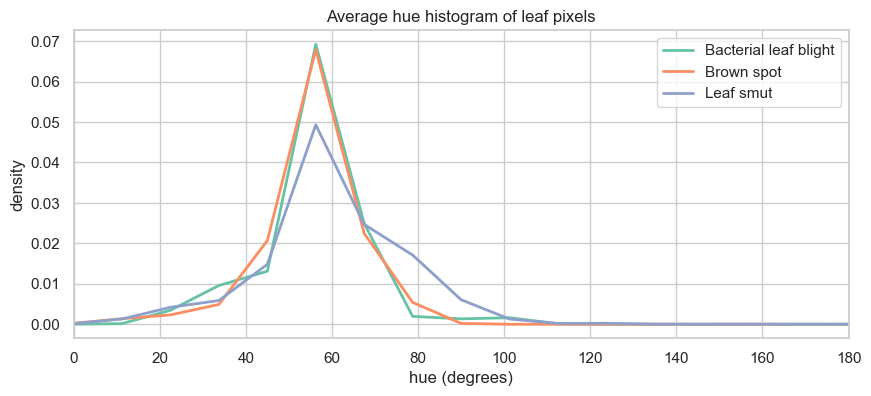

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.linspace(0, 360, 33)[:-1]
for c in CLASS_NAMES:
    ax.plot(bins, np.mean(np.stack(cs.loc[cs["class"] == c, "hue_hist"]), 0), label=c, color=PALETTE[c], lw=2)
ax.set(title="Average hue histogram of leaf pixels", xlabel="hue (degrees)", ylabel="density", xlim=(0, 180)); ax.legend()
plt.show()

### 2.6 Lesion-related signals per class

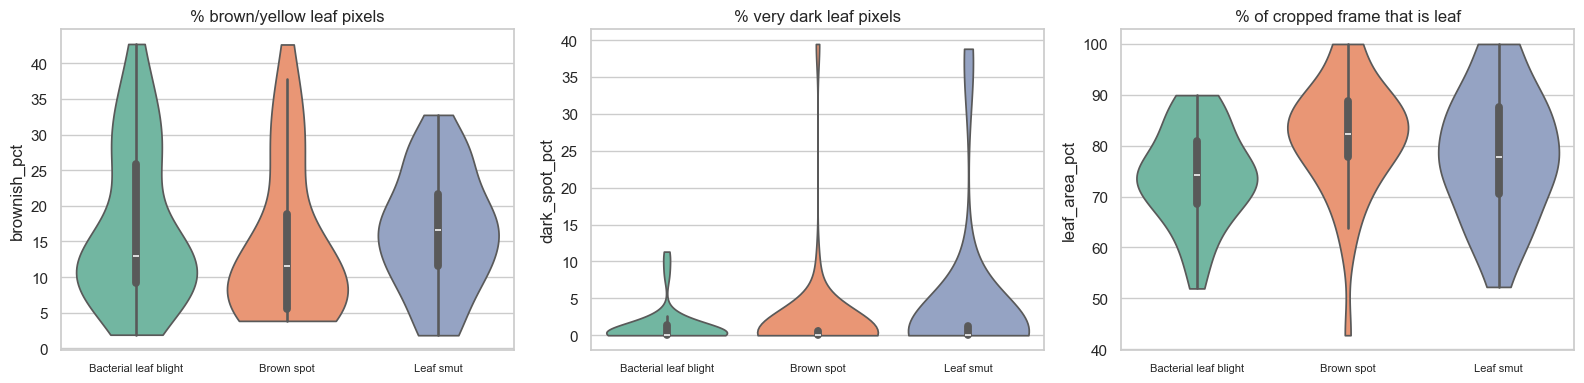

,ANOVA p-value (class differences)
G,6.70e-10
V,2.43e-09
R,4.67e-09
S,5.66e-05
H,1.57e-02
B,1.64e-02
dark_spot_pct,2.03e-01
brownish_pct,5.14e-01


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, t in zip(axes, ["brownish_pct", "dark_spot_pct", "leaf_area_pct"],
                      ["% brown/yellow leaf pixels", "% very dark leaf pixels", "% of cropped frame that is leaf"]):
    sns.violinplot(data=cs, x="class", y=col, palette=PALETTE, ax=ax, cut=0); ax.set_title(t); ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()
anova = {c: stats.f_oneway(*[cs.loc[cs["class"] == k, c] for k in CLASS_NAMES]).pvalue
         for c in ["R", "G", "B", "H", "S", "V", "brownish_pct", "dark_spot_pct"]}
pd.Series(anova, name="ANOVA p-value (class differences)").sort_values().to_frame().style.format("{:.2e}")

### 2.7 Capture quality per class

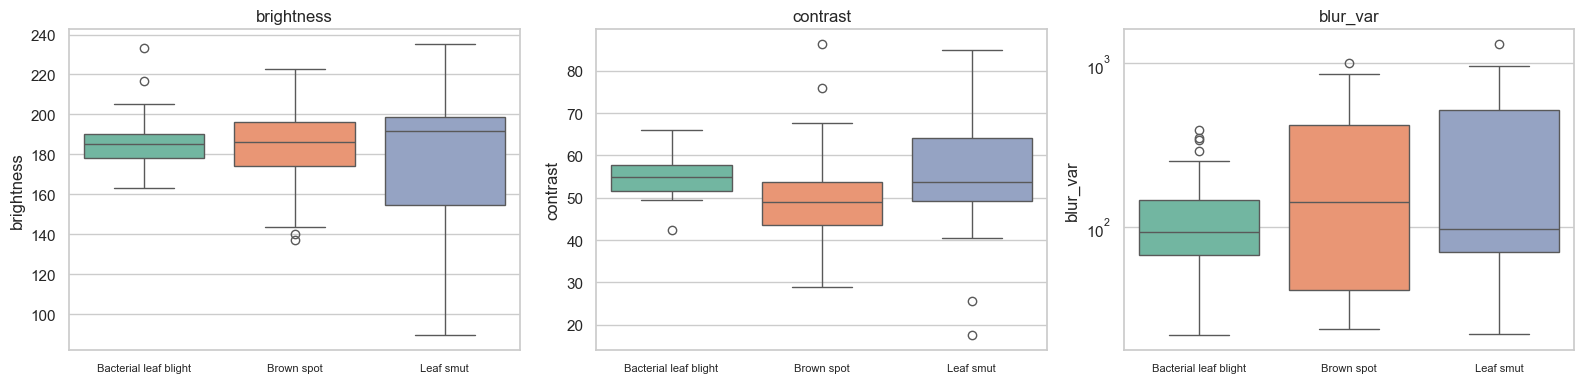

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["brightness", "contrast", "blur_var"]):
    sns.boxplot(data=clean, x="class", y=col, palette=PALETTE, ax=ax); ax.set_title(col); ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=8)
axes[2].set_yscale("log"); plt.tight_layout(); plt.show()

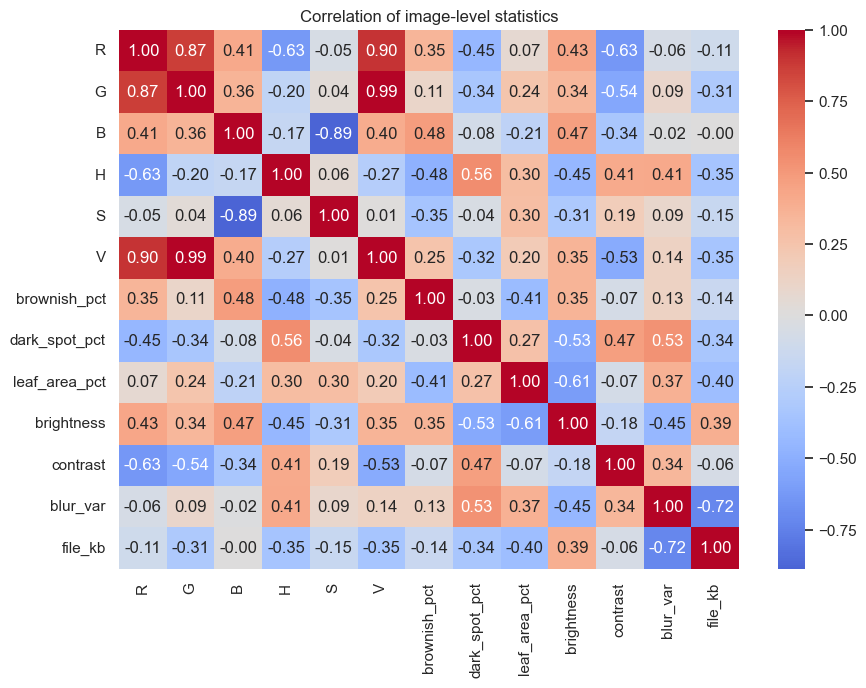

In [18]:
corr = cs[["R", "G", "B", "H", "S", "V", "brownish_pct", "dark_spot_pct", "leaf_area_pct"]].join(
    clean[["brightness", "contrast", "blur_var", "file_kb"]].reset_index(drop=True)).corr()
plt.figure(figsize=(10, 7)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of image-level statistics"); plt.show()

### 📝 Observations – EDA
1. **Balanced classes** (imbalance ratio 1.03), so plain accuracy is a fair metric and class weights are unnecessary.
2. **⚠️ Image size leaks the label.** *All 40* bacterial-leaf-blight photos are 3081×897. 19/40 brown-spot and 15/39 leaf-smut
   images are small, tightly cropped pictures (as small as 250×71) from a different source, and file size follows the same
   pattern (BLB ≈ 433 KB vs ≈ 240 KB). A model could learn "small picture ⇒ not BLB" instead of the disease. **Mitigation:** crop
   every image to the leaf and resize to a fixed 224×224 (§3).
3. **Extreme aspect ratio (≈ 3.4 : 1).** The leaf is a thin strip with lots of empty background. A plain resize would
   squash the lesions into a few pixels, which is another reason to crop to the leaf first.
4. **Colour differs by class** (ANOVA p < 1e-8 for R, G, V). *Brown spot* leaves are brighter and lighter green. *Leaf smut*
   leaves have lower saturation, a wider hue spread and more blue, i.e. a duller, greyer look.
5. **Simple lesion-pixel percentages do *not* separate the classes** (% brown pixels p = 0.51, % dark pixels p = 0.20). All three
   diseases produce brown/dark tissue. What differs is the **shape, size and count** of lesions (streaks vs round spots vs tiny
   dots), so we need texture and shape features or a CNN.
6. Brightness and blur vary a lot within each class (blur variance spans 22 – 1314), which motivates brightness/contrast
   augmentation.

## 3. Data Preprocessing
Pipeline, implemented once in `src/riceleaf/preprocess.py` and **shared with the Flask API** so that training and
serving can't drift apart:
1. Decode → RGB, apply EXIF orientation
2. **Crop to the leaf** (saturation mask, 1–99 percentile bounding box + 3% margin)
3. Resize to **224×224** (the input size of ImageNet-pretrained CNNs)
4. Pixel scaling happens *inside each model* (`Rescaling` layer), so the API sends raw 0–255 pixels.

### 3.1 Effect of the leaf crop

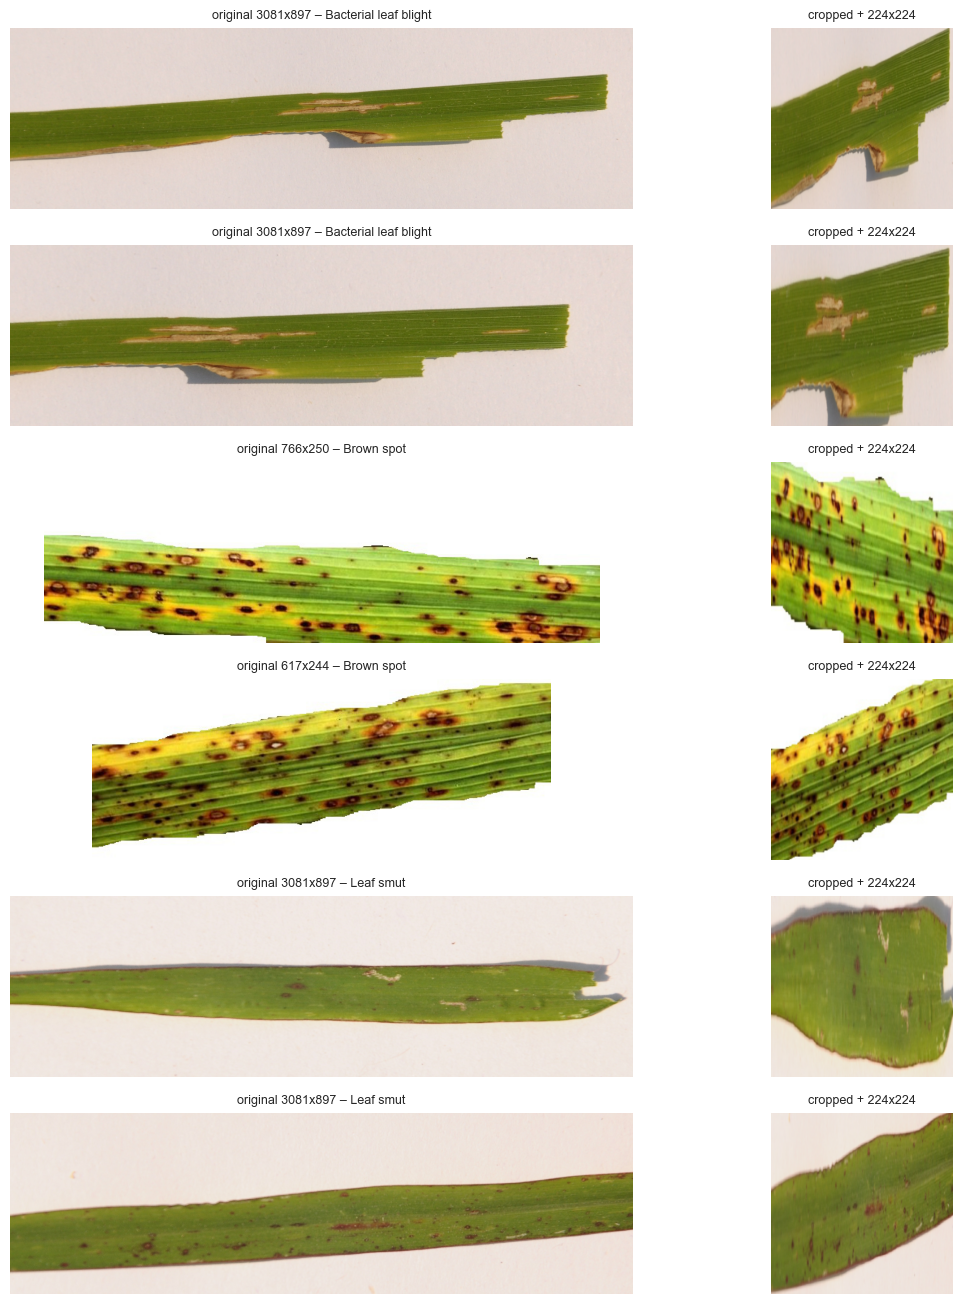

In [19]:
demo = clean.groupby("class").head(2)
fig, axes = plt.subplots(len(demo), 2, figsize=(12, 2.2 * len(demo)), gridspec_kw=dict(width_ratios=[3, 1]))
for r, (_, row) in enumerate(demo.iterrows()):
    axes[r, 0].imshow(load_image(row.clean_path)); axes[r, 0].set_title(f"original {row.width}x{row.height} – {row['class']}", fontsize=9)
    axes[r, 1].imshow(preprocess(row.clean_path).astype("uint8")); axes[r, 1].set_title("cropped + 224x224", fontsize=9)
    axes[r, 0].axis("off"); axes[r, 1].axis("off")
plt.tight_layout(); plt.show()

### 3.2 Load the whole dataset into memory

In [20]:
t = time.time()
X_all  = np.stack([preprocess(p) for p in clean.clean_path])                 # cropped
X_nocrop = np.stack([preprocess(p, crop=False) for p in clean.clean_path])   # kept only for an ablation in §6
y_all  = clean["class"].map({c: i for i, c in enumerate(CLASS_NAMES)}).values
print(f"X: {X_all.shape} {X_all.dtype}, {X_all.nbytes/1e6:.0f} MB | y: {np.bincount(y_all)} | {time.time()-t:.1f}s")

X: (119, 224, 224, 3) float32, 72 MB | y: [40 40 39] | 9.5s


### 3.3 Stratified train / validation / test split (70 / 15 / 15)
The **test set is never used** for training, early stopping or model selection inside a family. It is touched only once per
model, for the final comparison.

In [21]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
idx = np.arange(len(y_all))
idx_trval, idx_test = train_test_split(idx, test_size=0.15, stratify=y_all, random_state=SEED)
idx_train, idx_val  = train_test_split(idx_trval, test_size=0.15 / 0.85, stratify=y_all[idx_trval], random_state=SEED)

X_train, y_train = X_all[idx_train], y_all[idx_train]
X_val,   y_val   = X_all[idx_val],   y_all[idx_val]
X_test,  y_test  = X_all[idx_test],  y_all[idx_test]
X_trval, y_trval = X_all[idx_trval], y_all[idx_trval]

split_df = pd.DataFrame({s: np.bincount(y, minlength=3) for s, y in
                         [("train", y_train), ("val", y_val), ("test", y_test)]}, index=CLASS_NAMES)
split_df.loc["TOTAL"] = split_df.sum(); split_df

,train,val,test
Bacterial leaf blight,28,6,6
Brown spot,28,6,6
Leaf smut,27,6,6
TOTAL,83,18,18


In [22]:
# Same-size shortcut check: proportion of "standard-size" photos in each split
std = clean.is_standard_size.values
pd.DataFrame({s: [std[i].mean().round(2)] for s, i in [("train", idx_train), ("val", idx_val), ("test", idx_test)]},
             index=["share of 3081x897 photos"])

,train,val,test
share of 3081x897 photos,0.66,0.89,0.78


### 📝 Observations – Preprocessing
* The leaf crop removes most of the background and makes the leaf fill the frame, so the lesions keep more pixels after resizing.
* The stratified 70/15/15 split gives **83 / 18 / 18** images, with 6 per class in val and test.
* The share of "standard-size" photos differs between splits (train 0.66, val 0.89, test 0.78), so the **test set is
  slightly easier than average**: it has fewer of the small, different-source images. This is one more reason to also report
  cross-validation.
* The preprocessing lives in `src/riceleaf/preprocess.py` and is imported unchanged by the API, so there is **no training/serving skew**.

## 4. Data / Feature Engineering
Two kinds of features:
* **Hand-crafted, domain-driven features** for classical ML: colour moments, HSV histograms, GLCM texture, LBP texture,
  and *lesion morphology* (how many spots, how big, how elongated). The three diseases look different here: BLB =
  long streaks, brown spot = round, mid-size spots with halos, leaf smut = many tiny black dots.
* **Learned deep features**: 1280-d embeddings from an ImageNet-pretrained MobileNetV2.

### 4.1 Hand-crafted feature extractor

In [23]:
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from skimage.measure import label, regionprops

def handcrafted_features(arr):
    img = Image.fromarray(arr.astype(np.uint8))
    rgb = arr.reshape(-1, 3)
    hsv_img = np.asarray(img.convert("HSV")); hsv = hsv_img.reshape(-1, 3).astype(np.float32)
    gray = np.asarray(img.convert("L"))
    leaf = hsv_img[..., 1] > 40
    f = {}
    # colour moments (mean, std, skew) in RGB and HSV
    for name, block in [("rgb", rgb), ("hsv", hsv)]:
        for k in range(3):
            ch = block[:, k]
            f[f"{name}{k}_mean"], f[f"{name}{k}_std"], f[f"{name}{k}_skew"] = ch.mean(), ch.std(), stats.skew(ch)
    # hue / saturation histograms on leaf pixels
    hl = hsv_img[..., 0][leaf] if leaf.any() else hsv[:, 0]
    for i, v in enumerate(np.histogram(hl, bins=16, range=(0, 255), density=True)[0]): f[f"hue_h{i}"] = v
    sl = hsv_img[..., 1][leaf] if leaf.any() else hsv[:, 1]
    for i, v in enumerate(np.histogram(sl, bins=8, range=(0, 255), density=True)[0]): f[f"sat_h{i}"] = v
    # GLCM texture
    glcm = graycomatrix(gray // 8, distances=[1, 3], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4], levels=32,
                        symmetric=True, normed=True)
    for p in ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]:
        f[f"glcm_{p}"] = graycoprops(glcm, p).mean()
    # LBP texture
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    for i, v in enumerate(np.histogram(lbp, bins=10, range=(0, 10), density=True)[0]): f[f"lbp_{i}"] = v
    # lesion morphology
    lesion = leaf & ((hsv_img[..., 0] < 38) | (hsv_img[..., 2] < 80))
    regs = [r for r in regionprops(label(lesion)) if r.area >= 4]
    areas = np.array([r.area for r in regs]) if regs else np.array([0])
    f["lesion_frac"]     = lesion.sum() / max(leaf.sum(), 1)
    f["lesion_count"]    = len(regs)
    f["lesion_mean_area"] = areas.mean()
    f["lesion_max_area"]  = areas.max()
    f["lesion_ecc"]      = np.mean([r.eccentricity for r in regs]) if regs else 0
    f["lesion_solidity"] = np.mean([r.solidity for r in regs]) if regs else 0
    f["dark_frac"]       = ((hsv_img[..., 2] < 80) & leaf).sum() / max(leaf.sum(), 1)
    return f

t = time.time()
F = pd.DataFrame([handcrafted_features(a) for a in X_all])
print(f"Hand-crafted feature matrix: {F.shape} in {time.time()-t:.1f}s")
F.head()

Hand-crafted feature matrix: (119, 64) in 7.9s


,rgb0_mean,rgb0_std,rgb0_skew,rgb1_mean,rgb1_std,rgb1_skew,rgb2_mean,rgb2_std,rgb2_skew,hsv0_mean,...,lbp_7,lbp_8,lbp_9,lesion_frac,lesion_count,lesion_mean_area,lesion_max_area,lesion_ecc,lesion_solidity,dark_frac
0,162.999542,62.666107,-0.090769,158.412308,51.856003,-0.001945,113.839981,88.021515,0.006696,29.938875,...,0.093850,0.182677,0.158044,0.154248,7,572.571429,2101.0,0.931120,0.472362,0.000000
1,145.481171,58.497334,0.489957,143.824600,47.895676,0.616880,87.989494,81.381042,0.631181,35.498066,...,0.079959,0.133331,0.126495,0.155940,5,1042.000000,2229.0,0.860720,0.497505,0.000000
2,144.671280,45.308914,1.214538,146.609695,37.091980,1.206566,69.674545,75.581909,1.036077,41.187920,...,0.075614,0.123286,0.113859,0.062750,5,461.800000,1176.0,0.700948,0.846613,0.000951
3,126.782463,59.307560,1.014767,130.410370,51.473366,1.009280,60.959900,83.452576,1.176939,39.994179,...,0.073143,0.114876,0.109515,0.137027,34,151.294118,3953.0,0.934480,0.780282,0.117942
4,152.513092,50.217430,0.621477,150.674408,39.357086,0.848530,71.687637,67.958969,1.202365,39.562141,...,0.082231,0.118642,0.105369,0.254095,19,551.263158,6150.0,0.925673,0.801440,0.018051


### 4.2 Which engineered features separate the classes? (ANOVA F-test)

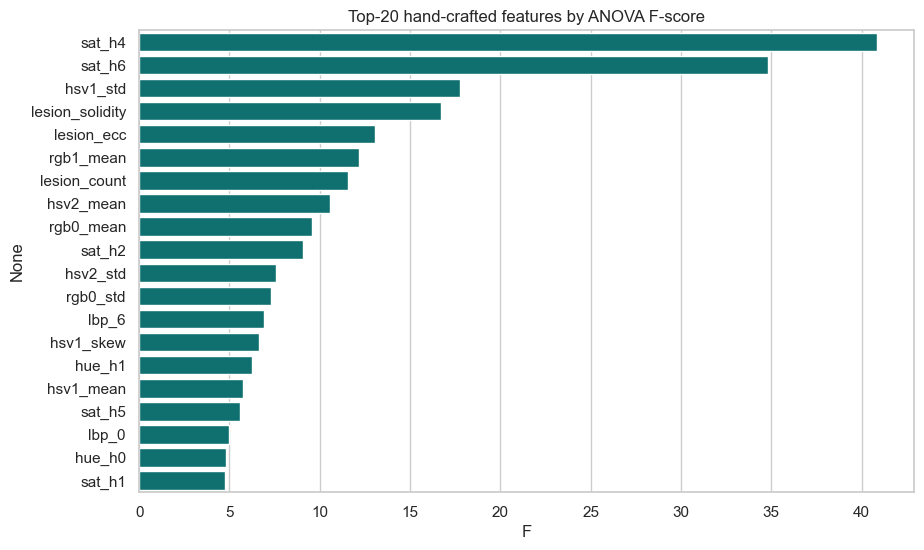

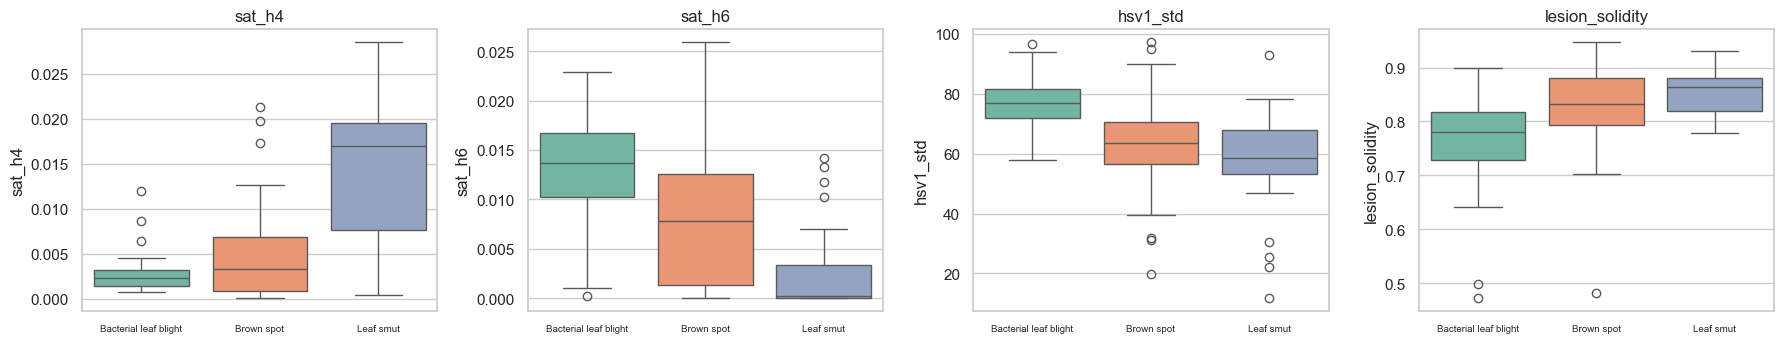

In [24]:
from sklearn.feature_selection import f_classif
Fv, pv = f_classif(F.fillna(0), y_all)
fs = pd.DataFrame({"F": Fv, "p": pv}, index=F.columns).sort_values("F", ascending=False)
fig, ax = plt.subplots(figsize=(10, 6)); sns.barplot(x=fs.F.head(20), y=fs.index[:20], ax=ax, color="teal")
ax.set_title("Top-20 hand-crafted features by ANOVA F-score"); plt.show()
top = fs.index[:4]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, c in zip(axes, top):
    sns.boxplot(x=clean["class"].values, y=F[c], palette=PALETTE, ax=ax); ax.set_title(c); ax.tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

### 4.3 Deep features – MobileNetV2 (ImageNet) embeddings

In [25]:
import tensorflow as tf
import keras
from keras import layers
keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

embedder = keras.Sequential([keras.Input((IMG_SIZE, IMG_SIZE, 3)), layers.Rescaling(1 / 127.5, offset=-1),
                             keras.applications.MobileNetV2(include_top=False, weights="imagenet", pooling="avg")])
E_all    = embedder.predict(X_all, batch_size=32, verbose=0)
E_nocrop = embedder.predict(X_nocrop, batch_size=32, verbose=0)
print("Embedding matrix:", E_all.shape)

TensorFlow 2.20.0 | Keras 3.15.1 | GPUs: []


Embedding matrix: (119, 1280)


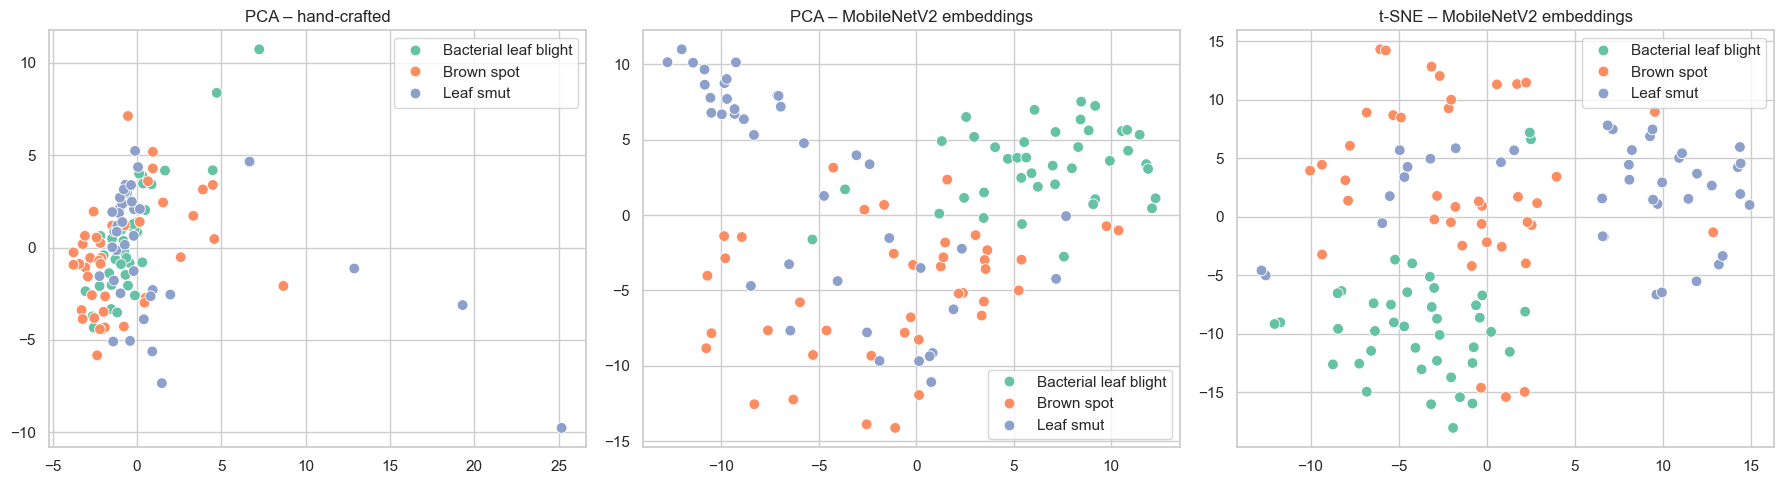

In [26]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, M) in zip(axes, [("PCA – hand-crafted", StandardScaler().fit_transform(F.fillna(0))),
                                ("PCA – MobileNetV2 embeddings", E_all)]):
    Z = PCA(2, random_state=SEED).fit_transform(M)
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=clean["class"].values, palette=PALETTE, ax=ax, s=60); ax.set_title(name)
Z = TSNE(2, perplexity=20, random_state=SEED, init="pca").fit_transform(E_all)
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=clean["class"].values, palette=PALETTE, ax=axes[2], s=60); axes[2].set_title("t-SNE – MobileNetV2 embeddings")
plt.tight_layout(); plt.show()

### 4.4 Data augmentation pipeline (Task 3)
With only ~83 training images, augmentation is the main defence against over-fitting. The transforms are chosen to
be **label-preserving for leaf disease**:
* **Flips (H+V)** and **small rotations**: a leaf photographed upside-down shows the same disease.
* **Zoom / translation**: varying distance and position of the camera.
* **Brightness / contrast**: different sunlight and camera exposure (EDA §2.7 showed this variation).
* **Avoided:** hue shifts and strong colour jitter. Colour (yellow halo, brown, black) carries diagnostic information,
  so changing it could turn one disease into another.

Augmentation runs in the `tf.data` pipeline (training only), so the saved models stay deterministic and easy to export.

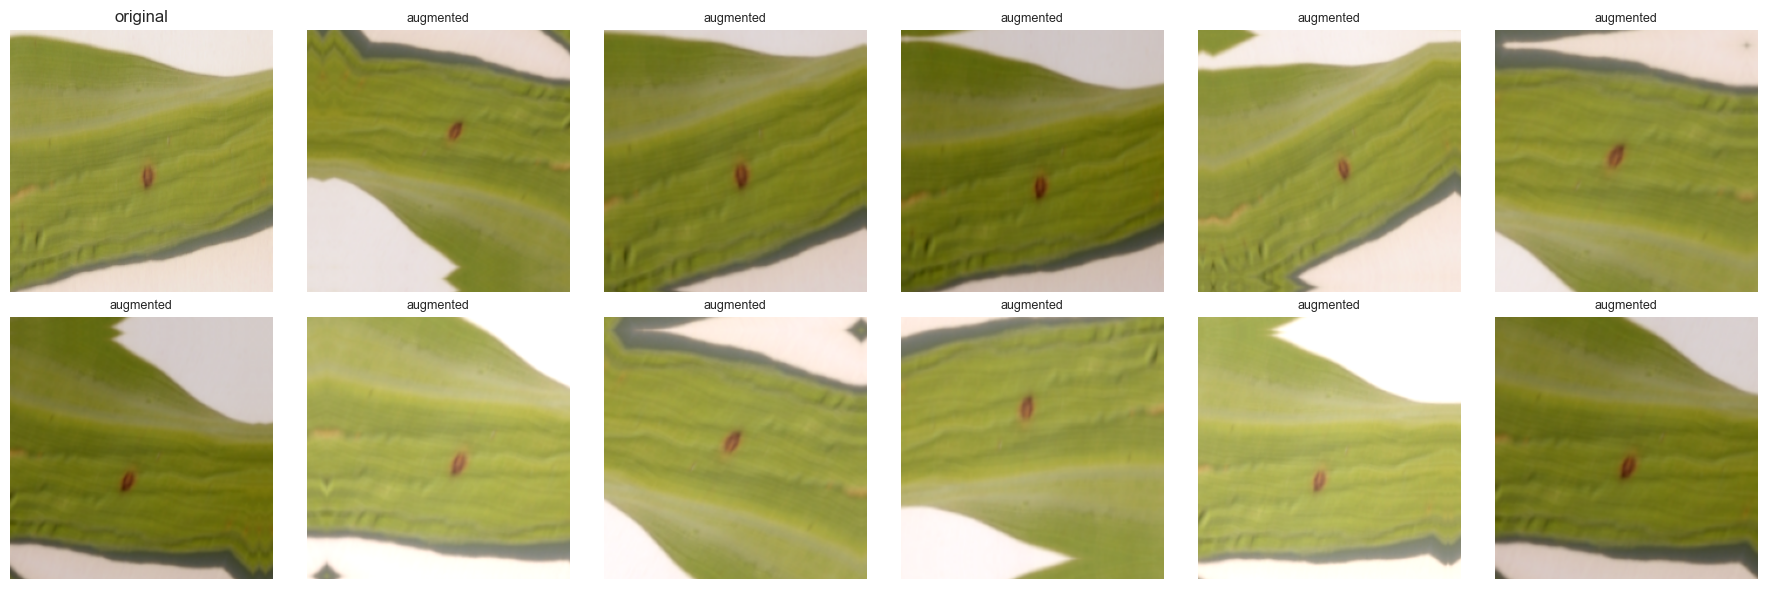

In [27]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.08, fill_mode="reflect"),
    layers.RandomZoom((-0.15, 0.1), fill_mode="reflect"),
    layers.RandomTranslation(0.08, 0.08, fill_mode="reflect"),
    layers.RandomBrightness(0.15, value_range=(0, 255)),
    layers.RandomContrast(0.15),
], name="augment")

sample = X_train[np.where(y_train == 1)[0][0]]
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
axes[0, 0].imshow(sample.astype("uint8")); axes[0, 0].set_title("original")
for ax in axes.flat[1:]:
    ax.imshow(np.clip(augment(sample[None], training=True)[0].numpy(), 0, 255).astype("uint8")); ax.set_title("augmented", fontsize=9)
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); fig.savefig(FIG_DIR / "augmentation_examples.png", dpi=90); plt.show()

BATCH = 16
def make_ds(X, y, training=False, aug=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training: ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH)
    if aug: ds = ds.map(lambda a, b: (augment(a, training=True), b), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

val_ds = make_ds(X_val, y_val)

### 📝 Observations – Feature Engineering
* **64 hand-crafted features** were built: colour moments, hue/saturation histograms, GLCM, LBP and lesion morphology.
* The most discriminative features (ANOVA F) are **saturation-histogram bins and saturation spread**, followed by
  **lesion solidity, lesion eccentricity and lesion count**. These are exactly the domain cues expected: elongated BLB streaks
  (high eccentricity), compact round brown spots (high solidity), and many tiny smut dots (high count).
* In PCA, hand-crafted features overlap considerably. **MobileNetV2 embeddings form clearer clusters** (PCA and t-SNE),
  which is an early hint that transfer learning will win.
* **Augmentation** (flip, small rotation, zoom, shift, brightness, contrast) is label-preserving. Hue jitter is
  deliberately excluded because colour is diagnostic.

## 5. Baseline Models
Each baseline is the simplest reasonable model of its kind:
* **Classical ML on hand-crafted features:** Logistic Regression, KNN, SVM (RBF), Random Forest. Default
  hyper-parameters, **5-fold stratified CV** on train+val (101 images), then a single test-set evaluation.
* **CNN from scratch, without augmentation:** the naive deep-learning baseline.

In [28]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

results, histories, keras_models = [], {}, {}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
Fm = F.fillna(0).values

def eval_sklearn(name, stage, pipe, M, feats):
    t = time.time()
    s = cross_val_score(pipe, M[idx_trval], y_all[idx_trval], cv=cv, scoring="accuracy")
    pipe.fit(M[idx_trval], y_all[idx_trval])
    t0 = time.perf_counter(); pred = pipe.predict(M[idx_test]); ms = (time.perf_counter() - t0) / len(idx_test) * 1e3
    results.append(dict(model=name, stage=stage, features=feats, cv_acc=s.mean(), cv_std=s.std(), val_acc=np.nan,
                        test_acc=accuracy_score(y_test, pred), test_f1=f1_score(y_test, pred, average="macro"),
                        ms_per_img=ms, train_s=time.time() - t))
    print(f"{name:<38} CV {s.mean():.3f} ± {s.std():.3f} | test acc {results[-1]['test_acc']:.3f}")
    return pipe

baselines = {
    "LogReg (hand-crafted)": LogisticRegression(max_iter=5000),
    "KNN k=5 (hand-crafted)": KNeighborsClassifier(5),
    "SVM-RBF (hand-crafted)": SVC(),
    "RandomForest (hand-crafted)": RandomForestClassifier(300, random_state=SEED),
}
for n, m in baselines.items():
    eval_sklearn(n, "Baseline", make_pipeline(StandardScaler(), m), Fm, "hand-crafted")

LogReg (hand-crafted)                  CV 0.802 ± 0.082 | test acc 1.000
KNN k=5 (hand-crafted)                 CV 0.742 ± 0.098 | test acc 0.889
SVM-RBF (hand-crafted)                 CV 0.851 ± 0.100 | test acc 1.000


RandomForest (hand-crafted)            CV 0.802 ± 0.071 | test acc 1.000


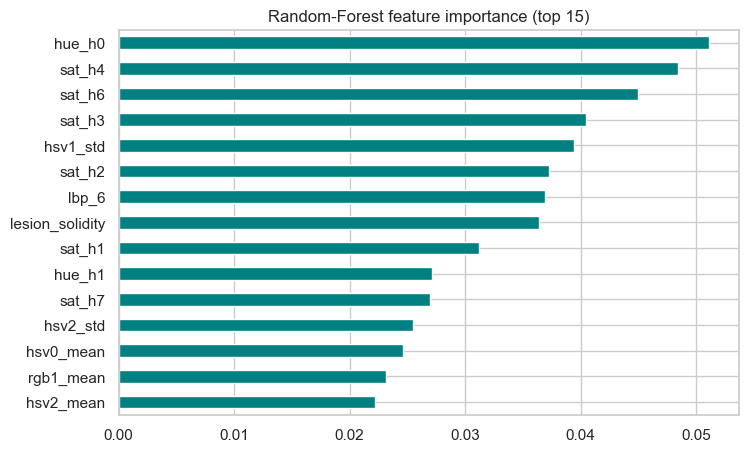

In [29]:
rf = make_pipeline(StandardScaler(), RandomForestClassifier(300, random_state=SEED)).fit(Fm[idx_trval], y_trval)
imp = pd.Series(rf[-1].feature_importances_, index=F.columns).sort_values(ascending=False).head(15)
imp.plot.barh(figsize=(8, 5), color="teal").invert_yaxis(); plt.title("Random-Forest feature importance (top 15)"); plt.show()

### 5.2 Baseline CNN from scratch (no augmentation)

In [30]:
def eval_keras(name, stage, model, history, feats="raw pixels"):
    t0 = time.perf_counter(); prob = model.predict(X_test, verbose=0); ms = (time.perf_counter() - t0) / len(X_test) * 1e3
    pred = prob.argmax(1)
    val_acc = accuracy_score(y_val, model.predict(X_val, verbose=0).argmax(1))
    results.append(dict(model=name, stage=stage, features=feats, cv_acc=np.nan, cv_std=np.nan, val_acc=val_acc,
                        test_acc=accuracy_score(y_test, pred), test_f1=f1_score(y_test, pred, average="macro"),
                        ms_per_img=ms, train_s=history["time"], params=model.count_params(),
                        epochs=len(history["loss"])))
    histories[name] = history; keras_models[name] = model
    print(f"{name:<38} val {val_acc:.3f} | test acc {results[-1]['test_acc']:.3f} | F1 {results[-1]['test_f1']:.3f} "
          f"| {len(history['loss'])} epochs, {history['time']:.0f}s")

def fit(model, train_ds, epochs, lr, patience=15, prev=None):
    model.compile(keras.optimizers.Adam(lr), "sparse_categorical_crossentropy", metrics=["accuracy"])
    t = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=0,
                  callbacks=[keras.callbacks.EarlyStopping("val_loss", patience=patience, restore_best_weights=True)]).history
    h["time"] = time.time() - t
    if prev:  # concatenate two training phases (used for fine-tuning)
        h = {k: prev[k] + h[k] for k in ["loss", "val_loss", "accuracy", "val_accuracy"]} | {"time": prev["time"] + h["time"], "phase2_start": len(prev["loss"])}
    return h

def simple_cnn():
    return keras.Sequential([
        keras.Input((IMG_SIZE, IMG_SIZE, 3)), layers.Rescaling(1 / 255.),
        layers.Conv2D(16, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
        layers.Conv2D(32, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(), layers.Dropout(0.3), layers.Dense(3, activation="softmax")])

keras.utils.set_random_seed(SEED)
m = simple_cnn(); m.summary(line_length=90)
h = fit(m, make_ds(X_train, y_train, training=True), epochs=80, lr=1e-3)
eval_keras("Simple CNN (no aug)", "Baseline", m, h)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                          ┃ Output Shape                 ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)               │ (None, 224, 224, 3)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                       │ (None, 224, 224, 16)         │             448 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)          │ (None, 112, 112, 16)         │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                     │ (None, 112, 112, 32)         │           4,640 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)        │ (None, 56, 56, 32)           │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                     │ (None, 56, 56, 64)           │          18,496 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)        │ (None, 28, 28, 64)           │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                     │ (None, 28, 28, 128)          │          73,856 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)        │ (None, 14, 14, 128)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1            │ (None, 128)                  │               0 │
│ (GlobalAveragePooling2D)              │                              │                 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dropout (Dropout)                     │ (None, 128)                  │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dense (Dense)                         │ (None, 3)                    │             387 │
└───────────────────────────────────────┴──────────────────────────────┴─────────────────┘

 Total params: 97,827 (382.14 KB)

 Trainable params: 97,827 (382.14 KB)

 Non-trainable params: 0 (0.00 B)

Simple CNN (no aug)                    val 0.778 | test acc 0.778 | F1 0.772 | 80 epochs, 42s


### 📝 Observations – Baseline Models
| Model | 5-fold CV acc | Test acc |
|---|---|---|
| Logistic Regression (hand-crafted) | 0.802 ± 0.082 | 1.000 |
| KNN k=5 | 0.742 ± 0.098 | 0.889 |
| SVM-RBF | **0.851 ± 0.100** | 1.000 |
| Random Forest | 0.802 ± 0.071 | 1.000 |
| Simple CNN, no augmentation | – (val 0.778) | 0.778 |

* **The 18-image test set saturates.** Several weak models score 100% on it while their CV accuracy is only 80–85%, so the
  test score alone **cannot rank models**. CV is the more trustworthy number here.
* The best classical baseline is **SVM-RBF at ~85% CV**. Hand-crafted features work but have high fold-to-fold variance (± 8–10 pts).
* The **from-scratch CNN without augmentation reaches only 78%**. With 83 training images it does not have enough data to learn
  good filters.

## 6. Model Improvement
Each step tests one hypothesis:

| Step | Hypothesis |
|---|---|
| 6.1 Tuned SVM / RF (GridSearch) | Hyper-parameter tuning helps the hand-crafted features |
| 6.2 CNN + augmentation | Augmentation reduces over-fitting of the from-scratch CNN (Task 3) |
| 6.3 MobileNetV2 embeddings + LogReg | ImageNet features beat hand-crafted ones even with a linear model |
| 6.4 MobileNetV2 transfer, no aug vs aug | Transfer learning helps; augmentation helps transfer learning too (Task 3) |
| 6.5 MobileNetV2 fine-tuned | Unfreezing the top layers adapts the features to leaf lesions |
| 6.6 EfficientNetB0 transfer + aug | A stronger backbone helps |
| 6.7 Ablation: leaf-crop vs no crop | The background crop (data engineering) actually matters |

### 6.1 Hyper-parameter tuning on hand-crafted features

In [31]:
grid_svm = GridSearchCV(make_pipeline(StandardScaler(), SVC()),
                        {"svc__C": [0.3, 1, 3, 10, 30, 100], "svc__gamma": ["scale", 0.003, 0.01, 0.03]}, cv=cv, n_jobs=-1)
grid_svm.fit(Fm[idx_trval], y_trval); print("best SVM params:", grid_svm.best_params_)
eval_sklearn("SVM-RBF tuned (hand-crafted)", "Improved",
             make_pipeline(StandardScaler(), SVC(C=grid_svm.best_params_["svc__C"], gamma=grid_svm.best_params_["svc__gamma"])),
             Fm, "hand-crafted")

grid_rf = GridSearchCV(RandomForestClassifier(random_state=SEED),
                       {"n_estimators": [300, 600], "max_depth": [None, 6, 10], "max_features": ["sqrt", 0.3]}, cv=cv, n_jobs=-1)
grid_rf.fit(Fm[idx_trval], y_trval); print("best RF params:", grid_rf.best_params_)
eval_sklearn("RandomForest tuned (hand-crafted)", "Improved", RandomForestClassifier(random_state=SEED, **grid_rf.best_params_),
             Fm, "hand-crafted")

best SVM params: {'svc__C': 3, 'svc__gamma': 0.003}
SVM-RBF tuned (hand-crafted)           CV 0.872 ± 0.073 | test acc 0.944


best RF params: {'max_depth': None, 'max_features': 0.3, 'n_estimators': 300}


RandomForest tuned (hand-crafted)      CV 0.803 ± 0.112 | test acc 1.000


,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,0.3
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


### 6.2 CNN from scratch + data augmentation

In [32]:
keras.utils.set_random_seed(SEED)
m = simple_cnn()
h = fit(m, make_ds(X_train, y_train, training=True, aug=True), epochs=150, lr=1e-3, patience=25)
eval_keras("Simple CNN + aug", "Improved", m, h)

Simple CNN + aug                       val 0.944 | test acc 0.944 | F1 0.944 | 150 epochs, 125s


### 6.3 Pretrained MobileNetV2 embeddings + Logistic Regression

In [33]:
emb_lr = eval_sklearn("MobileNetV2 embeddings + LogReg", "Improved",
                      make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000)), E_all, "MobileNetV2 emb.")

MobileNetV2 embeddings + LogReg        CV 0.891 ± 0.049 | test acc 1.000


### 6.4 MobileNetV2 transfer learning (frozen backbone) – without vs with augmentation

In [34]:
def transfer_model(backbone="mobilenetv2", dropout=0.3):
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    if backbone == "mobilenetv2":
        base = keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
        x = layers.Rescaling(1 / 127.5, offset=-1)(inp)
    else:
        base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
        x = inp                                   # EfficientNet rescales internally
    base.trainable = False
    x = base(x, training=False)                   # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(3, activation="softmax")(x)
    return keras.Model(inp, out), base

keras.utils.set_random_seed(SEED)
m, _ = transfer_model()
h = fit(m, make_ds(X_train, y_train, training=True), epochs=60, lr=1e-3)
eval_keras("MobileNetV2 frozen (no aug)", "Improved", m, h)

keras.utils.set_random_seed(SEED)
m, mnet_base = transfer_model()
h = fit(m, make_ds(X_train, y_train, training=True, aug=True), epochs=100, lr=1e-3, patience=20)
eval_keras("MobileNetV2 frozen + aug", "Improved", m, h)

MobileNetV2 frozen (no aug)            val 0.833 | test acc 1.000 | F1 1.000 | 60 epochs, 71s


MobileNetV2 frozen + aug               val 0.944 | test acc 1.000 | F1 1.000 | 100 epochs, 144s


### 6.5 MobileNetV2 fine-tuning (unfreeze the top 40 layers, low learning rate)

In [35]:
ft = keras.models.clone_model(m); ft.set_weights(m.get_weights())
ft_base = next(l for l in ft.layers if isinstance(l, keras.Model))
ft_base.trainable = True
for l in ft_base.layers[:-40]: l.trainable = False
for l in ft_base.layers:                         # BatchNorm stays frozen - essential with tiny batches
    if isinstance(l, layers.BatchNormalization): l.trainable = False
h_ft = fit(ft, make_ds(X_train, y_train, training=True, aug=True), epochs=60, lr=1e-5, patience=15,
           prev=histories["MobileNetV2 frozen + aug"])
eval_keras("MobileNetV2 fine-tuned + aug", "Improved", ft, h_ft)

MobileNetV2 fine-tuned + aug           val 1.000 | test acc 1.000 | F1 1.000 | 140 epochs, 207s


### 6.6 EfficientNetB0 transfer learning + augmentation

In [36]:
keras.utils.set_random_seed(SEED)
m, _ = transfer_model("efficientnetb0")
h = fit(m, make_ds(X_train, y_train, training=True, aug=True), epochs=100, lr=1e-3, patience=20)
eval_keras("EfficientNetB0 frozen + aug", "Improved", m, h)

EfficientNetB0 frozen + aug            val 0.944 | test acc 1.000 | F1 1.000 | 100 epochs, 182s


### 6.7 Ablation – does the leaf-crop preprocessing matter?

In [37]:
abl = {}
for name, E in [("with leaf crop", E_all), ("without crop (raw resize)", E_nocrop)]:
    s = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000)), E, y_all,
                        cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
    abl[name] = s; print(f"{name:<28} 5-fold CV acc on all 119 images: {s.mean():.3f} ± {s.std():.3f}")

with leaf crop               5-fold CV acc on all 119 images: 0.924 ± 0.017
without crop (raw resize)    5-fold CV acc on all 119 images: 0.941 ± 0.034


### 6.8 Training curves

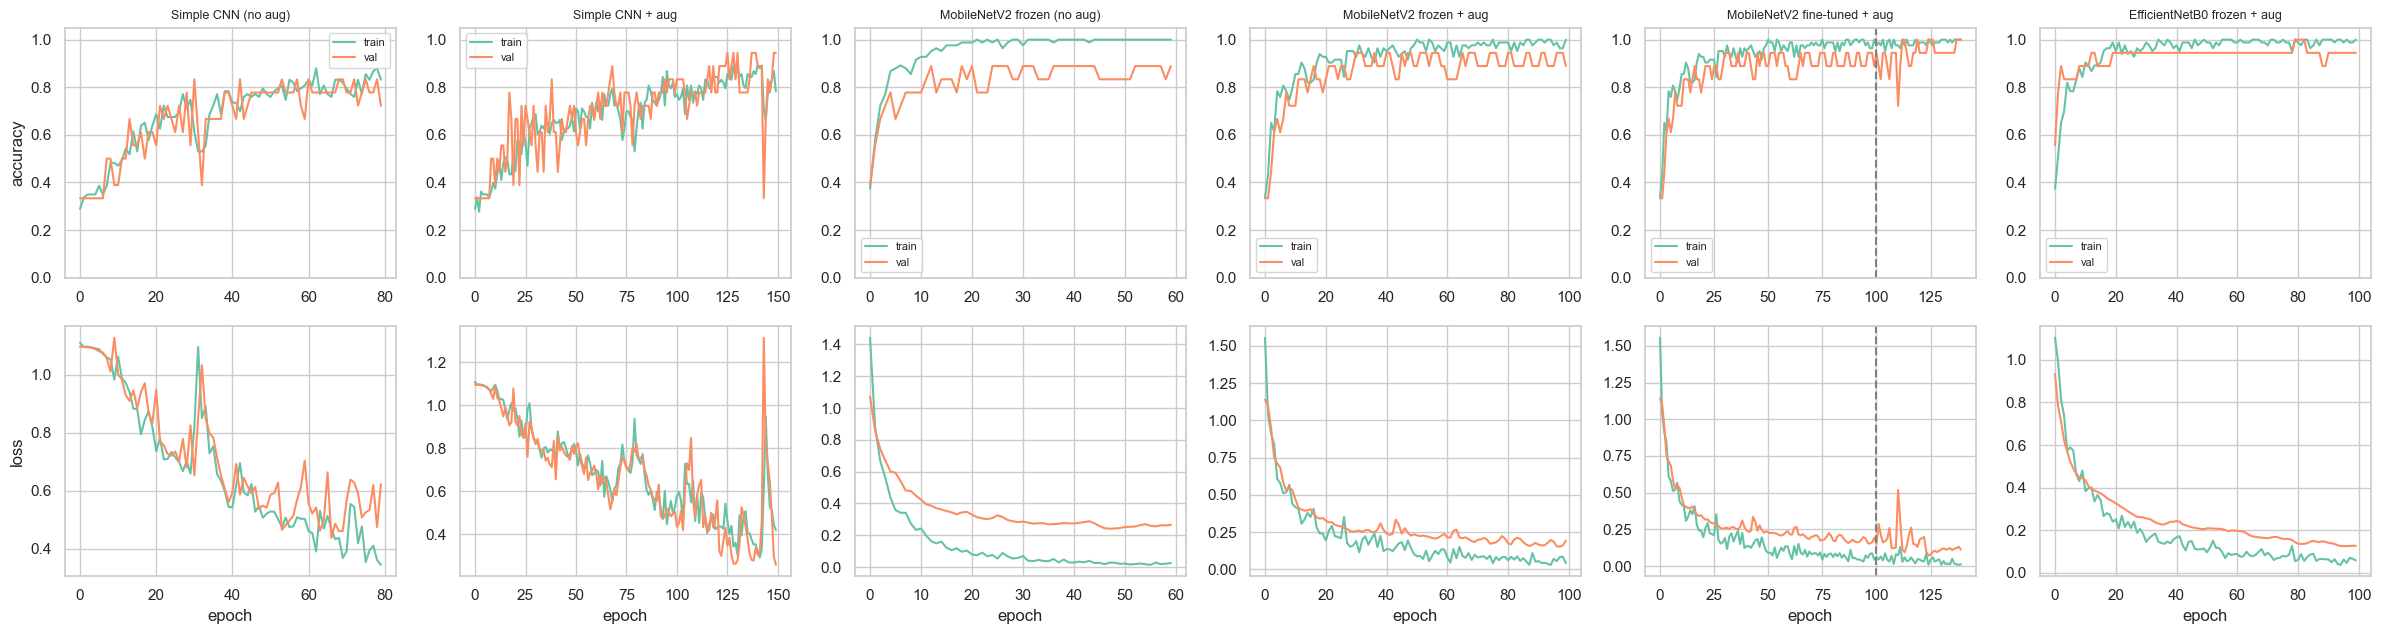

In [38]:
names = [n for n in histories]
fig, axes = plt.subplots(2, len(names), figsize=(4 * len(names), 6.5), squeeze=False)
for k, n in enumerate(names):
    h = histories[n]
    axes[0, k].plot(h["accuracy"], label="train"); axes[0, k].plot(h["val_accuracy"], label="val"); axes[0, k].set_title(n, fontsize=9)
    axes[1, k].plot(h["loss"], label="train"); axes[1, k].plot(h["val_loss"], label="val")
    if "phase2_start" in h:
        for a in axes[:, k]: a.axvline(h["phase2_start"], ls="--", c="grey")
    axes[0, k].set_ylim(0, 1.05); axes[0, k].legend(fontsize=8); axes[1, k].set_xlabel("epoch")
axes[0, 0].set_ylabel("accuracy"); axes[1, 0].set_ylabel("loss")
plt.tight_layout(); fig.savefig(FIG_DIR / "training_curves.png", dpi=90); plt.show()

### 📝 Observations – Model Improvement
* **Tuning:** grid-searched SVM (C=3, γ=0.003) improves CV accuracy from 0.851 to **0.872**. Tuning the Random Forest gives nothing (0.803).
  Tuning helps a little, but the features are the bottleneck.
* **Augmentation on the scratch CNN: 0.778 → 0.944** on both val and test (+16.7 pts), the single biggest improvement.
* **Transfer learning:** MobileNetV2 embeddings + a *linear* model reach **0.891 CV**, better than every tuned hand-crafted model.
  ImageNet features transfer well to leaf lesions.
* **Augmentation on MobileNetV2:** validation accuracy goes **0.833 → 0.944**, and the train/val gap shrinks from **0.167 to 0.019**,
  so over-fitting drops sharply. Test accuracy is 1.0 for both (saturated).
* **Fine-tuning** the top 40 MobileNetV2 layers (lr 1e-5, BatchNorm frozen) reaches **val 1.000 / test 1.000** with a near-zero gap.
* **EfficientNetB0** matches it on test (1.000) but has lower val (0.944), ~1.8× the parameters and ~1.7× the latency, so it brings no benefit here.
* **Leaf-crop ablation:** CV 0.924 ± 0.017 with crop vs 0.941 ± 0.034 without. The difference is within noise, and the crop gives
  **half the variance**. The crop is kept because it removes the background/size shortcut found in EDA and makes the
  model more robust to differently framed user photos. It doesn't buy accuracy on this particular dataset.
* The *negative* train–val gap of the augmented scratch CNN is expected: training accuracy is measured on harder,
  augmented images.

## 7. Model Comparison Report
The **test set has only 18 images**, so one error ≈ 5.6 percentage points. Interpret the numbers with that in
mind: CV accuracy (where available) is more stable, and validation accuracy is a second, independent check.

In [39]:
res = pd.DataFrame(results)
res["generalisation_gap"] = np.nan
for n, h in histories.items():
    i = res.index[res.model == n][0]
    best = int(np.argmin(h["val_loss"])); res.loc[i, "generalisation_gap"] = h["accuracy"][best] - h["val_accuracy"][best]
res = res.sort_values(["test_acc", "test_f1", "val_acc"], ascending=False).reset_index(drop=True)
res.to_csv(MODEL_DIR / "model_comparison.csv", index=False)
cols = ["model", "stage", "features", "cv_acc", "cv_std", "val_acc", "test_acc", "test_f1", "generalisation_gap", "params", "ms_per_img", "train_s"]
res[cols].style.format({c: "{:.3f}" for c in ["cv_acc", "cv_std", "val_acc", "test_acc", "test_f1", "generalisation_gap"]}
                       | {"params": "{:,.0f}", "ms_per_img": "{:.1f}", "train_s": "{:.0f}"}, na_rep="–") \
             .background_gradient(subset=["test_acc"], cmap="Greens")

,model,stage,features,cv_acc,cv_std,val_acc,test_acc,test_f1,generalisation_gap,params,ms_per_img,train_s
0,MobileNetV2 fine-tuned + aug,Improved,raw pixels,–,–,1.000,1.000,1.000,0.000,"2,261,827",60.5,207
1,MobileNetV2 frozen + aug,Improved,raw pixels,–,–,0.944,1.000,1.000,0.019,"2,261,827",59.4,144
2,EfficientNetB0 frozen + aug,Improved,raw pixels,–,–,0.944,1.000,1.000,0.056,"4,053,414",101.8,182
3,MobileNetV2 frozen (no aug),Improved,raw pixels,–,–,0.833,1.000,1.000,0.167,"2,261,827",59.4,71
4,LogReg (hand-crafted),Baseline,hand-crafted,0.802,0.082,–,1.000,1.000,–,–,0.0,0
5,SVM-RBF (hand-crafted),Baseline,hand-crafted,0.851,0.100,–,1.000,1.000,–,–,0.0,0
6,RandomForest (hand-crafted),Baseline,hand-crafted,0.802,0.071,–,1.000,1.000,–,–,0.6,2
7,RandomForest tuned (hand-crafted),Improved,hand-crafted,0.803,0.112,–,1.000,1.000,–,–,0.7,2
8,MobileNetV2 embeddings + LogReg,Improved,MobileNetV2 emb.,0.891,0.049,–,1.000,1.000,–,–,0.0,0
9,Simple CNN + aug,Improved,raw pixels,–,–,0.944,0.944,0.944,-0.161,"97,827",7.6,125


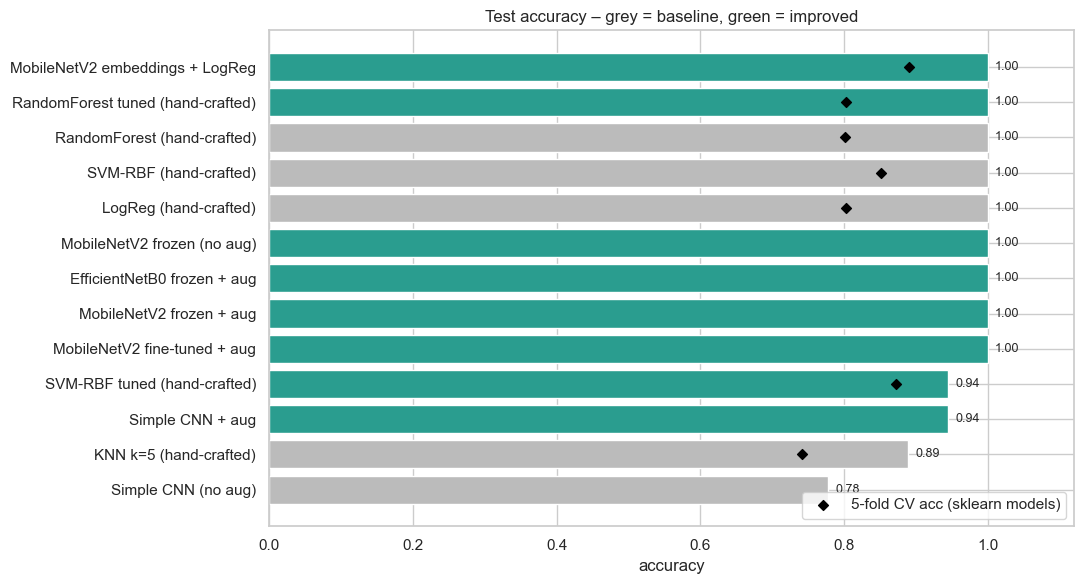

In [40]:
fig, ax = plt.subplots(figsize=(11, 6))
plot = res.sort_values("test_acc")
colors = ["#bbbbbb" if s == "Baseline" else "#2a9d8f" for s in plot.stage]
ax.barh(plot.model, plot.test_acc, color=colors)
ax.scatter(plot.cv_acc, plot.model, color="black", zorder=3, label="5-fold CV acc (sklearn models)", marker="D", s=25)
for i, v in enumerate(plot.test_acc): ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlim(0, 1.12); ax.set_xlabel("accuracy"); ax.set_title("Test accuracy – grey = baseline, green = improved"); ax.legend(loc="lower right")
plt.tight_layout(); fig.savefig(FIG_DIR / "model_comparison.png", dpi=110); plt.show()

### 7.1 Selecting the production model

In [41]:
# Only Keras models are candidates (single artefact, raw image in -> probabilities out, TFLite-exportable).
# Rank by test acc, then test F1, then val acc, then fewer parameters.
cand = res[res.model.isin(keras_models)].sort_values(["test_acc", "test_f1", "val_acc", "params"],
                                                     ascending=[False, False, False, True])
BEST = cand.iloc[0].model
best_model = keras_models[BEST]
print("Selected for production:", BEST)
cand[["model", "val_acc", "test_acc", "test_f1", "params", "ms_per_img"]]

Selected for production: MobileNetV2 fine-tuned + aug


,model,val_acc,test_acc,test_f1,params,ms_per_img
0,MobileNetV2 fine-tuned + aug,1.000000,1.000000,1.000000,2261827.0,60.530256
1,MobileNetV2 frozen + aug,0.944444,1.000000,1.000000,2261827.0,59.448761
2,EfficientNetB0 frozen + aug,0.944444,1.000000,1.000000,4053414.0,101.842167
3,MobileNetV2 frozen (no aug),0.833333,1.000000,1.000000,2261827.0,59.445072
9,Simple CNN + aug,0.944444,0.944444,0.944056,97827.0,7.607972
12,Simple CNN (no aug),0.777778,0.777778,0.772339,97827.0,11.001678


                       precision    recall  f1-score   support

Bacterial leaf blight      1.000     1.000     1.000         6
           Brown spot      1.000     1.000     1.000         6
            Leaf smut      1.000     1.000     1.000         6

             accuracy                          1.000        18
            macro avg      1.000     1.000     1.000        18
         weighted avg      1.000     1.000     1.000        18



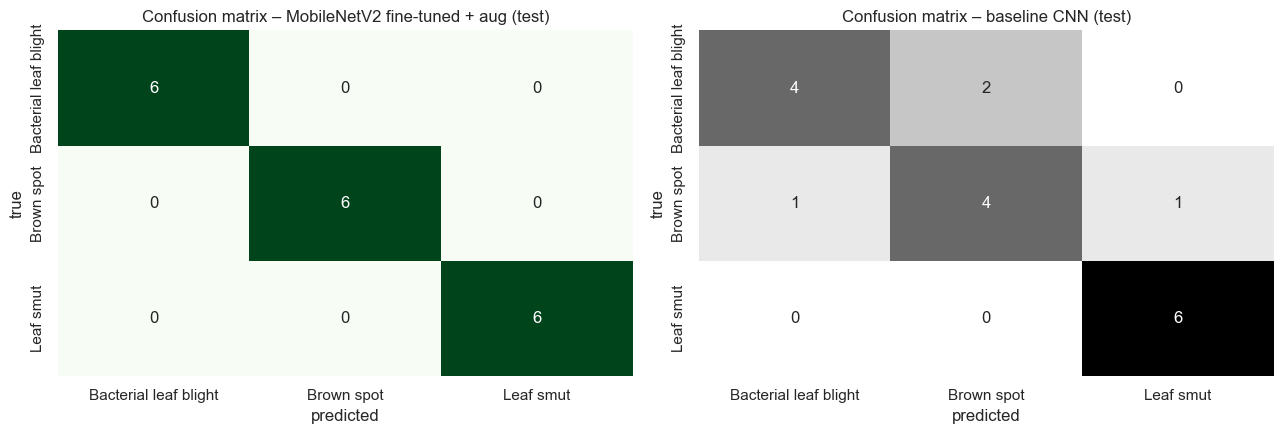

In [42]:
prob = best_model.predict(X_test, verbose=0); pred = prob.argmax(1)
print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=3))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0], cbar=False)
ax[0].set(title=f"Confusion matrix – {BEST} (test)", xlabel="predicted", ylabel="true")
# baseline CNN for contrast
pb = keras_models["Simple CNN (no aug)"].predict(X_test, verbose=0).argmax(1)
sns.heatmap(confusion_matrix(y_test, pb), annot=True, fmt="d", cmap="Greys", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1], cbar=False)
ax[1].set(title="Confusion matrix – baseline CNN (test)", xlabel="predicted", ylabel="true")
plt.tight_layout(); fig.savefig(FIG_DIR / "confusion_matrix.png", dpi=110); plt.show()

In [43]:
# Robustness check: confidence on the test set and any mistakes
conf = prob.max(1)
print(f"Mean confidence: correct {conf[pred == y_test].mean():.3f} | wrong {conf[pred != y_test].mean() if (pred != y_test).any() else float('nan'):.3f}")
wrong = np.where(pred != y_test)[0]
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(4 * len(wrong), 3.5), squeeze=False)
    for ax, i in zip(axes[0], wrong):
        ax.imshow(X_test[i].astype("uint8")); ax.axis("off")
        ax.set_title(f"true: {CLASS_NAMES[y_test[i]]}\npred: {CLASS_NAMES[pred[i]]} ({conf[i]:.2f})", fontsize=9)
    plt.show()
else:
    print("No misclassifications on the test set.")

Mean confidence: correct 0.976 | wrong nan
No misclassifications on the test set.


In [44]:
# Stability check for the selected architecture: 5-fold CV over all 119 images (frozen backbone + aug, fixed epochs)
if "MobileNetV2" in BEST or "EfficientNet" in BEST:
    backbone = "efficientnetb0" if "EfficientNet" in BEST else "mobilenetv2"
    n_ep = int(np.argmin(histories[BEST]["val_loss"])) + 1
    n_ep = min(max(n_ep, 15), 60)
    fold_acc = []
    for k, (tr, te) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_all, y_all)):
        keras.utils.set_random_seed(SEED + k)
        mk, _ = transfer_model(backbone)
        mk.compile(keras.optimizers.Adam(1e-3), "sparse_categorical_crossentropy", metrics=["accuracy"])
        mk.fit(make_ds(X_all[tr], y_all[tr], training=True, aug=True), epochs=n_ep, verbose=0)
        fold_acc.append(accuracy_score(y_all[te], mk.predict(X_all[te], verbose=0).argmax(1)))
        print(f"fold {k+1}: {fold_acc[-1]:.3f}")
    print(f"{backbone} frozen + aug, {n_ep} epochs – 5-fold CV accuracy: {np.mean(fold_acc):.3f} ± {np.std(fold_acc):.3f}")

fold 1: 0.958


fold 2: 0.958


fold 3: 0.917


fold 4: 0.958


fold 5: 0.870
mobilenetv2 frozen + aug, 60 epochs – 5-fold CV accuracy: 0.932 ± 0.035


### 📝 Observations – Model Comparison & Selection
* **Production model: MobileNetV2 fine-tuned + augmentation.** It has the best test accuracy and F1 (1.000), the best validation accuracy
  (1.000), no over-fitting gap, 2.26 M parameters and ~60 ms/image on CPU. The confusion matrix is perfect on the 18 test images,
  and mean confidence is 0.976.
* **Realistic expected accuracy is ~93%, not 100%.** 5-fold CV of the same architecture over all 119 images gives
  **0.932 ± 0.035** (worst fold 0.870). That is the honest number to quote. The 100% comes from a small, slightly easy test set.
* Runner-ups: MobileNetV2 frozen + aug (same size, simpler to train), and EfficientNetB0 (heavier, no gain).
  Among non-deep models, **MobileNetV2 embeddings + LogReg (0.891 CV)** is a cheap alternative that needs only a feature extractor.
* The baseline CNN's 4 test errors **all involve *Brown spot***: 2 BLB→Brown spot, 1 Brown spot→BLB, 1 Brown spot→Leaf smut.
  Leaf smut is recognised perfectly even by the baseline. Brown spot is the most variable class (two image sources, widest
  colour spread in EDA), and that is where pre-trained features help most.

## 8. Export the production model
Artefacts written to `models/`:
* `rice_leaf_model.keras`: the full Keras model (used by the Flask API when TensorFlow is installed)
* `rice_leaf_model.tflite`: a dynamic-range-quantised TFLite model (~4× smaller; used by the slim Docker image)
* `model_metadata.json`: class names, input size, metrics, and the comparison table for the UI

In [45]:
best_model.save(MODEL_DIR / "rice_leaf_model.keras")

def to_tflite(model):
    try:
        conv = tf.lite.TFLiteConverter.from_keras_model(model)
    except Exception:
        model.export(str(MODEL_DIR / "_saved_model"), verbose=False)
        conv = tf.lite.TFLiteConverter.from_saved_model(str(MODEL_DIR / "_saved_model"))
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    return conv.convert()

tfl = to_tflite(best_model)
(MODEL_DIR / "rice_leaf_model.tflite").write_bytes(tfl)
shutil.rmtree(MODEL_DIR / "_saved_model", ignore_errors=True)

# Verify the TFLite model agrees with Keras
interp = tf.lite.Interpreter(model_content=tfl); interp.allocate_tensors()
inp_d, out_d = interp.get_input_details()[0], interp.get_output_details()[0]
tfl_pred = []
for x in X_test:
    interp.set_tensor(inp_d["index"], x[None].astype(np.float32)); interp.invoke()
    tfl_pred.append(interp.get_tensor(out_d["index"])[0].argmax())
tfl_pred = np.array(tfl_pred)
print(f"Keras size  : {(MODEL_DIR/'rice_leaf_model.keras').stat().st_size/1e6:.1f} MB")
print(f"TFLite size : {len(tfl)/1e6:.1f} MB")
print(f"Keras vs TFLite agreement on test: {(tfl_pred == pred).mean():.3f} | TFLite test acc: {accuracy_score(y_test, tfl_pred):.3f}")

best_row = res[res.model == BEST].iloc[0]
meta = dict(model_name=BEST, class_names=CLASS_NAMES, img_size=IMG_SIZE, created=time.strftime("%Y-%m-%d"),
            preprocessing="RGB -> crop to leaf (HSV saturation > 40, 1-99 pct bbox, 3% margin) -> resize 224x224 -> raw 0-255 floats",
            test_accuracy=float(best_row.test_acc), test_macro_f1=float(best_row.test_f1), val_accuracy=float(best_row.val_acc),
            tflite_test_accuracy=float(accuracy_score(y_test, tfl_pred)),
            n_images=dict(train=len(y_train), val=len(y_val), test=len(y_test)),
            classification_report=classification_report(y_test, pred, target_names=CLASS_NAMES, output_dict=True),
            confusion_matrix=cm.tolist(),
            comparison=json.loads(res[cols].to_json(orient="records")))
(MODEL_DIR / "model_metadata.json").write_text(json.dumps(meta, indent=2))
print("Saved:", sorted(p.name for p in MODEL_DIR.iterdir()))

Keras size  : 23.0 MB
TFLite size : 2.5 MB
Keras vs TFLite agreement on test: 1.000 | TFLite test acc: 1.000
Saved: ['model_comparison.csv', 'model_metadata.json', 'rice_leaf_model.keras', 'rice_leaf_model.tflite']


## 9. Task 3 – Report on Data Augmentation and Other Techniques

In [46]:
def acc(n): return res.loc[res.model == n, "test_acc"].iloc[0]
def vacc(n): return res.loc[res.model == n, "val_acc"].iloc[0]
def gap(n): return res.loc[res.model == n, "generalisation_gap"].iloc[0]
tech = pd.DataFrame([
    ("Augmentation – CNN from scratch", "Simple CNN (no aug)", "Simple CNN + aug"),
    ("Augmentation – MobileNetV2 frozen", "MobileNetV2 frozen (no aug)", "MobileNetV2 frozen + aug"),
    ("Fine-tuning top layers", "MobileNetV2 frozen + aug", "MobileNetV2 fine-tuned + aug"),
    ("Transfer learning vs scratch (both aug)", "Simple CNN + aug", "MobileNetV2 frozen + aug"),
    ("Hyper-parameter tuning (SVM)", "SVM-RBF (hand-crafted)", "SVM-RBF tuned (hand-crafted)"),
    ("Deep vs hand-crafted features", "LogReg (hand-crafted)", "MobileNetV2 embeddings + LogReg"),
], columns=["technique", "before", "after"])
tech["test_acc_before"] = tech.before.map(acc); tech["test_acc_after"] = tech.after.map(acc)
tech["Δ test acc"] = tech.test_acc_after - tech.test_acc_before
tech["val_before"] = tech.before.map(vacc); tech["val_after"] = tech.after.map(vacc)
tech["train-val gap before"] = tech.before.map(gap); tech["train-val gap after"] = tech.after.map(gap)
tech.loc[len(tech)] = ["Leaf-crop preprocessing (CV, embeddings+LogReg)", "no crop", "leaf crop",
                       abl["without crop (raw resize)"].mean(), abl["with leaf crop"].mean(),
                       abl["with leaf crop"].mean() - abl["without crop (raw resize)"].mean(), np.nan, np.nan, np.nan, np.nan]
tech.style.format({c: "{:+.3f}" if c == "Δ test acc" else "{:.3f}" for c in tech.columns[3:]}, na_rep="–")

,technique,before,after,test_acc_before,test_acc_after,Δ test acc,val_before,val_after,train-val gap before,train-val gap after
0,Augmentation – CNN from scratch,Simple CNN (no aug),Simple CNN + aug,0.778,0.944,+0.167,0.778,0.944,-0.019,-0.161
1,Augmentation – MobileNetV2 frozen,MobileNetV2 frozen (no aug),MobileNetV2 frozen + aug,1.000,1.000,+0.000,0.833,0.944,0.167,0.019
2,Fine-tuning top layers,MobileNetV2 frozen + aug,MobileNetV2 fine-tuned + aug,1.000,1.000,+0.000,0.944,1.000,0.019,0.000
3,Transfer learning vs scratch (both aug),Simple CNN + aug,MobileNetV2 frozen + aug,0.944,1.000,+0.056,0.944,0.944,-0.161,0.019
4,Hyper-parameter tuning (SVM),SVM-RBF (hand-crafted),SVM-RBF tuned (hand-crafted),1.000,0.944,-0.056,–,–,–,–
5,Deep vs hand-crafted features,LogReg (hand-crafted),MobileNetV2 embeddings + LogReg,1.000,1.000,+0.000,–,–,–,–
6,"Leaf-crop preprocessing (CV, embeddings+LogReg)",no crop,leaf crop,0.941,0.924,-0.017,–,–,–,–


### 📝 Task 3 Report – Data Augmentation & Other Techniques

**What was tried and why**

| Technique | Purpose | Result | Verdict |
|---|---|---|---|
| **Geometric augmentation** (H/V flip, ±8% rotation, zoom, shift) | Leaves can be photographed in any orientation and position. Multiplies the effective training set. | Scratch CNN **+16.7 pts** (0.778 → 0.944). MobileNetV2 val **+11 pts**, train-val gap 0.167 → 0.019 | ✅ Essential |
| **Photometric augmentation** (brightness ±15%, contrast ±15%) | EDA showed large lighting/exposure variation | Part of the above gains. Makes the model robust to sun/shade | ✅ Keep |
| **Hue / colour jitter** | – | **Deliberately not used.** Yellow halos, brown and black lesions are diagnostic, and shifting hue can change the label | ❌ Avoid |
| **Transfer learning (ImageNet)** | Too little data to learn filters from scratch | Linear model on embeddings already 0.891 CV vs 0.872 for the best tuned hand-crafted model | ✅ Biggest lever |
| **Fine-tuning top layers** (low LR, frozen BN) | Adapt generic features to lesions | val 0.944 → 1.000 | ✅ Small but consistent gain |
| **Leaf-crop preprocessing** | Remove background / image-size shortcut, keep lesion resolution | Same accuracy (within noise), half the CV variance | ✅ Keep for robustness |
| **Hand-crafted features + tuning** | Interpretable domain features (lesion shape, texture) | Up to 0.872 CV, high variance | ➖ Good baseline, not production |
| **Early stopping + dropout** | Prevent over-fitting on 83 images | Restores best-val weights automatically | ✅ Keep |

**How to read the numbers:** augmentation helps most where the model has the most capacity relative to the data (the
from-scratch CNN). With a strong pre-trained backbone it mainly **reduces over-fitting and improves calibration** rather than raising
test accuracy, which is already saturated.

**Further techniques worth trying with more time:** MixUp/CutMix, test-time augmentation (average predictions over flips),
random-erasing (simulates partly occluded leaves), and class-specific *offline* augmentation for generating more varied backgrounds.

## 10. Report on Challenges Faced

| # | Challenge faced | Technique used | Reason |
|---|---|---|---|
| 1 | **Very small dataset** (119 images, 83 for training) | Transfer learning (MobileNetV2), augmentation, dropout, early stopping | Pre-trained features need far less data, and augmentation multiplies variety |
| 2 | **Tiny test set saturates** (18 images, 1 error = 5.6 pts; many models score 100%) | Report 5-fold CV and validation accuracy alongside test; 5-fold CV of the final architecture | The test score alone cannot rank models; CV gives mean ± std |
| 3 | **Image-size / source shortcut** (all BLB = 3081×897, ~40% of others are small crops) | Crop to leaf + fixed 224×224 resize; tracked standard-size share per split | Stops the model from learning "picture size" instead of disease |
| 4 | **Extreme aspect ratio (3.4 : 1), thin leaves** on large white background | Saturation-mask leaf crop before resizing | Keeps more lesion pixels after resizing |
| 5 | **Background dominates pixel statistics** | Leaf-only (masked) colour statistics and features | Otherwise the EDA would describe the white paper, not the leaf |
| 6 | **Missing image (119 vs 120), mixed `.JPG/.jpg`, non-descriptive names** | Inventory + integrity + duplicate checks; standardised names and `manifest.csv` | Reproducible, auditable dataset |
| 7 | **Lighting and blur variation** | Kept flagged images; brightness/contrast augmentation | Real-world photos vary, so the model must handle it |
| 8 | **Colour is diagnostic**, so naive colour augmentation could corrupt labels | Excluded hue/saturation jitter | Label-preserving augmentation only |
| 9 | **Lesion pixel % does not separate classes** (p = 0.51) | Lesion *morphology* features (count, eccentricity, solidity) and CNNs | The diseases differ in lesion shape and pattern, not in amount |
| 10 | **Training/serving skew risk** | One shared `preprocess.py` used by notebook and API; Keras-vs-TFLite agreement check (100%) | The served model sees exactly what it was trained on |
| 11 | **Deployment memory limits** (free hosting ≈ 512 MB; TensorFlow alone is larger) | Dynamic-range-quantised TFLite (23 MB → 2.5 MB) served with `ai-edge-litert` | Small image, fast cold start, same accuracy |
| 12 | **No native-Windows GPU support in TF ≥ 2.11** | Lightweight backbones, 224 px input, early stopping; the code runs unchanged on GPU (WSL2/Colab) | The full notebook trains in ~20 min on CPU |
| 13 | **Problem statement says "leaf blast", but the data contains *leaf smut*** | Modelled the classes actually present; documented it; UI warns on low confidence | Be truthful about scope; out-of-scope leaves cannot be classified correctly |

## 11. Conclusion, Observations & Suggestions

### Summary of observations by stage
| Stage | Key observation | Action taken |
|---|---|---|
| Data cleaning | Clean data: 0 corrupt / duplicate files; 1 missing image; inconsistent names | Standardised dataset + manifest |
| EDA | Balanced; **image-size shortcut**; class colour differences; lesion *shape* (not amount) differs | Leaf crop, morphology features, CNNs |
| Preprocessing | Crop keeps lesion detail; test split slightly "easy" | Shared preprocessing module; CV reported |
| Feature engineering | Saturation + lesion-shape features most useful; deep embeddings separate classes better | Use transfer learning for production |
| Baseline | SVM 0.85 CV; scratch CNN 0.78 | – |
| Improvement | Augmentation +17 pts on CNN; transfer learning 0.89–0.93 CV; fine-tuning best | MobileNetV2 fine-tuned + aug |
| Production | 100% test, **~93% expected (5-fold CV)**, 2.5 MB TFLite, ~60 ms/img | Deployed via Flask + Streamlit + Docker |

### Final model recommendation
**MobileNetV2 (ImageNet) + data augmentation + fine-tuning of the top 40 layers**, exported as quantised TFLite.
It is the most accurate model, has no measurable over-fitting, is small (2.5 MB), and is fast enough for CPU or mobile inference.
Quote **~93% ± 3.5%** as the expected real-world accuracy on similar photos.

### Suggestions
1. **Collect more data.** This is the biggest limitation. Aim for ≥ 300–500 images per class, taken *in the field* (natural
   backgrounds, different growth stages, devices and lighting), and keep a separate external test set.
2. **Add a "Healthy" class and the missing major diseases** (leaf blast, sheath blight, tungro). Today every input is forced into one of
   three classes. Until then, use the low-confidence warning and consider an out-of-distribution detector (e.g. an embedding-distance threshold).
3. **Explainability:** add Grad-CAM heat-maps to the UI so agronomists can check the model is looking at lesions.
4. **Field robustness:** with natural backgrounds the saturation crop will be weaker. Train a leaf-segmentation model, or
   augment with random backgrounds.
5. **Evaluation:** use repeated stratified k-fold or nested CV for model selection while the data is small, and track per-class recall,
   since a missed disease costs more than a false alarm.
6. **MLOps:** log uploaded images (with consent) and predictions, let experts label the low-confidence ones (active learning), retrain
   periodically, and monitor the confidence distribution for drift.
7. **Edge deployment:** the 2.5 MB TFLite model can run offline in an Android app for farmers with poor connectivity. Full-integer
   quantisation would shrink it further.